# Imports

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# Set default parameters for plots
sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline
# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

# Function Setup

In [2]:
# gRNA properties

# This is a new PAM dict that shows the position of the central
# bp of the 33bp dCas9 footprint, which is the 5th bp upstream of PAM.
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict = {'g1': -27,
            'g2': -22,
            'g3': -5,
            'g4': 12,
            'g5': 23,
            'g6': 25,
            'g8': 43,
            'g9': 50,
            'g10': 67,
            'g11': 101,
            'g12': 156,
            'g13': 160,
           }

strand_dict = {'g1': 'right',
               'g2': 'left',
               'g3': 'right',
               'g4': 'right',
               'g5': 'left',
               'g6': 'right',
               'g8': 'right',
               'g9': 'left',
               'g10': 'left',
               'g11': 'right',
               'g12': 'right',
               'g13': 'left',
              }

def strand_to_footprint(PAM, strand):
    '''
    PAM is an integer.
    strand is a string that is 'right' or 'left'.
    '''
    if strand == 'right':
        rightwindow = PAM + 8 # 9bp overhang beyond gRNA. N in NGG already included.
        leftwindow = PAM - 20 - 1 #1bp overhang beyond gRNA.
    elif strand == 'left':
        rightwindow = PAM + 20 + 1
        leftwindow = PAM - 8
    else:
        raise('Problem with strand')
    return leftwindow, rightwindow

In [3]:
# Helper functions

def Hill_rep_fun(x, params):
    '''
    Hill repression function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def Hill_act_fun(x, params):
    '''
    Hill activation function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b * np.exp(n*(np.log(x) - np.log(K))) / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def symlog_transform(x, linthresh=1.0):
    return np.sign(x) * (np.log1p(np.abs(x / linthresh)))
def symlog_inverse(y, linthresh=1.0):
    return np.sign(y) * linthresh * (np.expm1(np.abs(y)))

def log_lognormal(x, mu, sigma):
    '''
    Returns the log prior for a lognormal distribution.
    Takes x as input in non-log-scaled value.
    To obtain a median of M for the distribution, must input mu = ln(M).
    '''
    return -np.log(x) - np.log(sigma) - 0.5 * np.log(2 * np.pi) - ((np.log(x) - mu) ** 2) / (2 * sigma**2)


In [4]:
# functions for emcee

def log_prior(theta, prior_params):     
    '''
    Lognormal priors for all four parameters.
    '''
    b, a, K, n = theta
    b_params, a_params, K_params, n_params = prior_params
    mub, sigmab = b_params
    mua, sigmaa = a_params
    muK, sigmaK = K_params
    mun, sigman = n_params
    
    # log-normal prior on beta
    logbprior = -np.log(b) - np.log(sigmab) - 0.5 * np.log(2 * np.pi) - ((np.log(b) - mub) ** 2) / (2 * sigmab**2)
    # log-normal prior on alpha
    logaprior = -np.log(a) - np.log(sigmaa) - 0.5 * np.log(2 * np.pi) - ((np.log(a) - mua) ** 2) / (2 * sigmaa**2)
    # log-normal prior on K
    logKprior = -np.log(K) - np.log(sigmaK) - 0.5 * np.log(2 * np.pi) - ((np.log(K) - muK) ** 2) / (2 * sigmaK**2)
    # log-normal prior on n
    lognprior =  -np.log(n) - np.log(sigman) - 0.5 * np.log(2 * np.pi) - ((np.log(n) - mun) ** 2) / (2 * sigman**2)
    
    return logbprior + logaprior + logKprior + lognprior

def log_likelihood(theta, x, y):
    '''
    Model is a Hill repression function, with output in ln() scale.
    This requires data, y, to also be in ln() scale.
    '''
    b, a, K, n = theta

    model = np.log(b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a) # <- this is ln(Hill rep function), written in numerically stable form
    
    cost = - np.linalg.norm(y - model) # <- Make sure the model and the data are appropriately log-transformed   
    cost_progress.append(cost)
    return cost


def log_probability(theta, x, y, prior_params):
    lp = log_prior(theta, prior_params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y)

In [5]:
def make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, fill=False, savefig=False, linthresh=1, filetype='png'):
    '''
    Inputs:
        fcs_dict_ls: list of gated fcs dictionaries arranged by replicate
        media: string, 'M9' or 'CL'
        grna: string, 'gN' where N is an integer
        rep: integer, 1,2,3
        atcs: list of strings of labels of atc concentrations (ng/mL).
              First entry is 'Blank'.
        fill: Boolean to determine if margin KDEs are filled or not.
    '''
    cmap = plt.get_cmap('viridis',len(atcs)-1)
    
    fcs_gated_dict = fcs_dict_ls[rep-1]
    
    plt.figure(figsize=(4,4))
    g = sns.JointGrid(space=0)

    med_gfps = np.empty(len(atcs))
    med_rfps = np.empty(len(atcs))
    for n in range(len(atcs)):
        fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        
        # calculate median gfp, rfp values for later
        med_gfps[n] = np.median(gfps)
        med_rfps[n] = np.median(rfps)
    
        # transform gfp, rfp values into symlog space
        symlog_gfps = symlog_transform(gfps, linthresh=linthresh)
        symlog_rfps = symlog_transform(rfps, linthresh=linthresh)
    
        # start filling plots
        if n==0:
            color = 'grey'
        else:
            color = cmap(n-1)
            
        sns.scatterplot(x=rfps, y=gfps, color=color,
                        s=2, alpha=0.1, ax=g.ax_joint,
                        legend=False)
        
        rfp_kde = stats.gaussian_kde(symlog_rfps)
        rfp_xrange = np.linspace(min(symlog_rfps), max(symlog_rfps), 1000)
        rfp_kde_y = rfp_kde(rfp_xrange)
        g.ax_marg_x.plot(symlog_inverse(rfp_xrange, linthresh=linthresh), rfp_kde_y, c=color)
        if fill:
            g.ax_marg_x.fill_between(symlog_inverse(rfp_xrange, linthresh=linthresh), np.zeros(len(rfp_kde_y)), rfp_kde_y, color=color, alpha=0.2)
        
        gfp_kde = stats.gaussian_kde(symlog_gfps)
        gfp_xrange = np.linspace(min(symlog_gfps), max(symlog_gfps), 1000)
        gfp_kde_y = gfp_kde(gfp_xrange)
        g.ax_marg_y.plot(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), c=color)
        if fill:
            g.ax_marg_y.fill_between(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), np.zeros(len(gfp_kde_y)), color=color, alpha=0.2)
    
    # plot medians
    g.ax_joint.scatter(med_rfps[0], med_gfps[0], c='k')
    g.ax_joint.scatter(med_rfps[1:], med_gfps[1:], c='r')
    
    g.ax_joint.set_xscale('symlog', linthresh=linthresh)
    g.ax_joint.set_yscale('log')
    g.ax_joint.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_marg_x.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_joint.set_ylim((1e0,5e6))
    g.ax_joint.set_xlim((-2e1,2e3))
    # g.ax_joint.set_ylim(bottom=1e0)
    g.ax_joint.set_xlabel('Repressor:RFP')
    g.ax_joint.set_ylabel('GFP')
    # g.ax_marg_x.set_title(grna + ', ' + media + ', Rep '+str(rep))
    print(grna + ', ' + media + ', Rep '+str(rep))
    
    if savefig:
        filename = 'D_' + grna + '_' + media + '_rep' + str(rep) + '_2Dplot.'+ filetype
        plt.savefig('./figs/2Dplots/'+filename, bbox_inches='tight')

    plt.show()

# Unpickle FCS data

In [6]:
with open('./pickles/241130_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_1 = pickle.load(f)
f.close()

with open('./pickles/241205_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_2 = pickle.load(f)
f.close()

with open('./pickles/241208_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_3 = pickle.load(f)
f.close()

# Plotting and analysis

## Single-cell GFP/RFP plots

Fig 3b, Fig 3c, Supplemental Figs 1-13

In [8]:
plot_inds_cl_1 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_1 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_cl_2 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_2 = [0, 0.02, 0.2, 0.43, 0.93, 2, 3.5, 6.3, 11.3, 20, 200]
plot_inds_cl_3 = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9_3 = [0, 0.2, 0.43, 0.93, 2, 2.6, 3.5, 6.3, 11.3, 20, 200]

plot_inds_ls = [[plot_inds_m9_1, plot_inds_cl_1],
                [plot_inds_m9_2, plot_inds_cl_2],
                [plot_inds_m9_3, plot_inds_cl_3],
               ]

atcs_cl_1 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_1 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_cl_2 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_2 = ['Blank','0','0.02','0.2','0.43','0.93','2','3.5','6.3','11.3','20','200']
atcs_cl_3 = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9_3 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','200']

atcs_ls = [[atcs_m9_1, atcs_cl_1],
            [atcs_m9_2, atcs_cl_2],
            [atcs_m9_3, atcs_cl_3],
          ]


medias = ['M9', 'CL']
reps = [1,2,3]
grnas = ['g1','g2','g3','g4','g5','g6',
         'g8','g9','g10','g11','g12','g13','g14']

fcs_dict_ls = [fcs_gated_dict_1,
          fcs_gated_dict_2,
          fcs_gated_dict_3,
         ]

NameError: name 'fcs_gated_dict_1' is not defined

g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

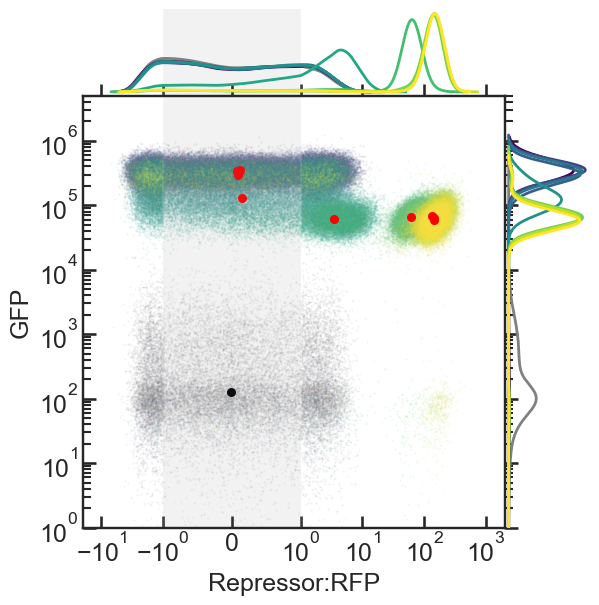

g1, M9, Rep 2


<Figure size 400x400 with 0 Axes>

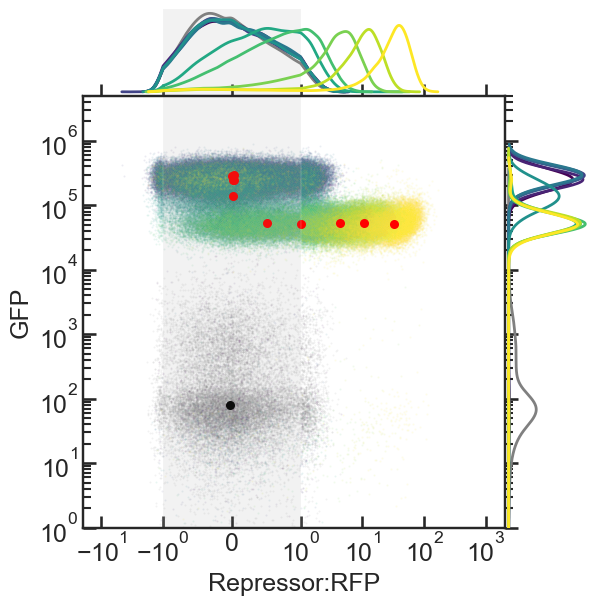

g1, M9, Rep 3


<Figure size 400x400 with 0 Axes>

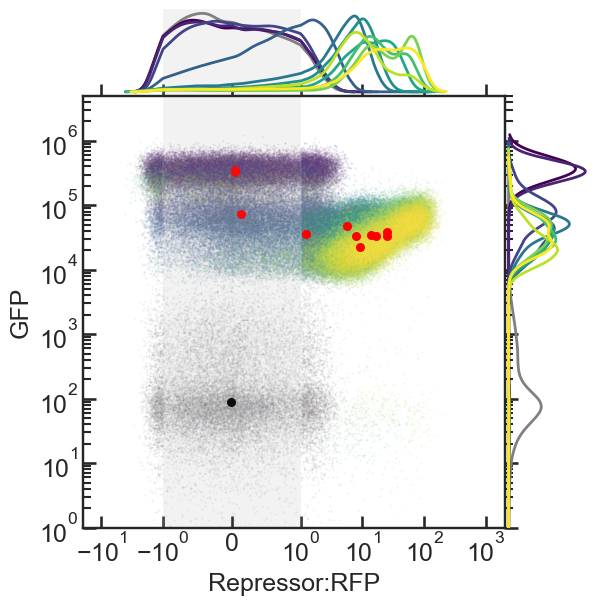

g1, CL, Rep 1


<Figure size 400x400 with 0 Axes>

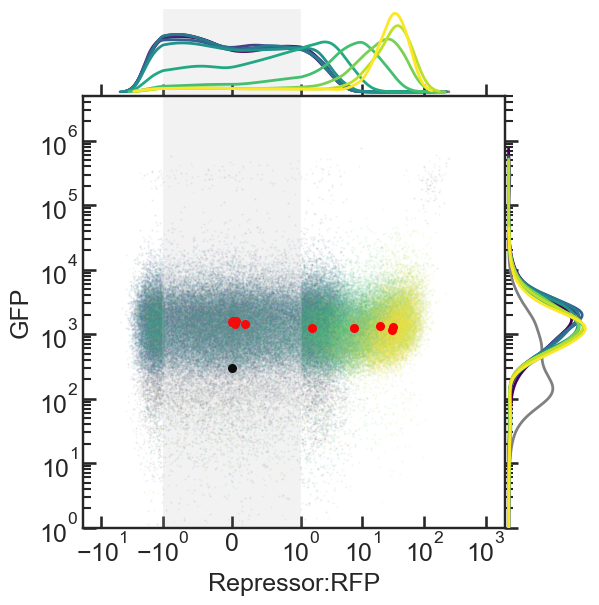

g1, CL, Rep 2


<Figure size 400x400 with 0 Axes>

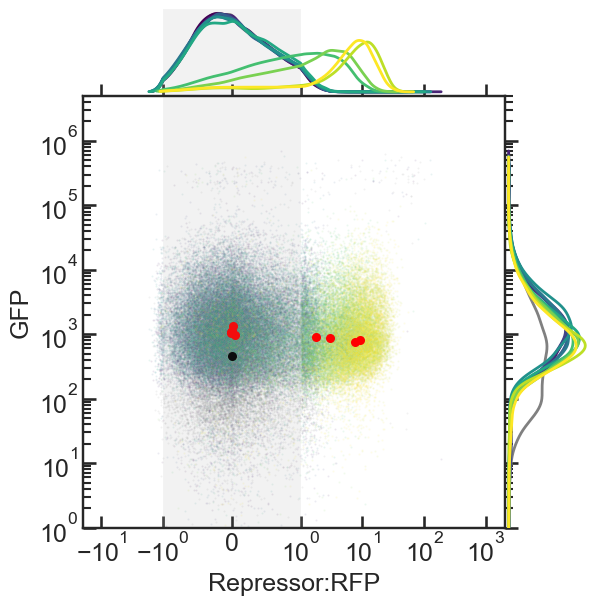

g1, CL, Rep 3


<Figure size 400x400 with 0 Axes>

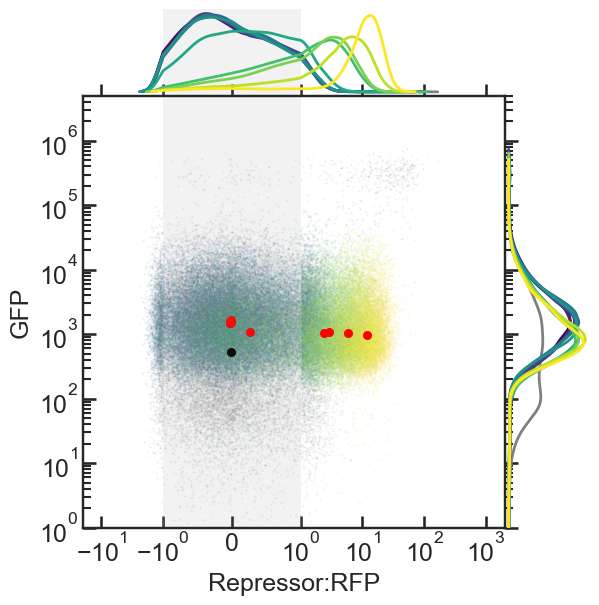

g2, M9, Rep 1


<Figure size 400x400 with 0 Axes>

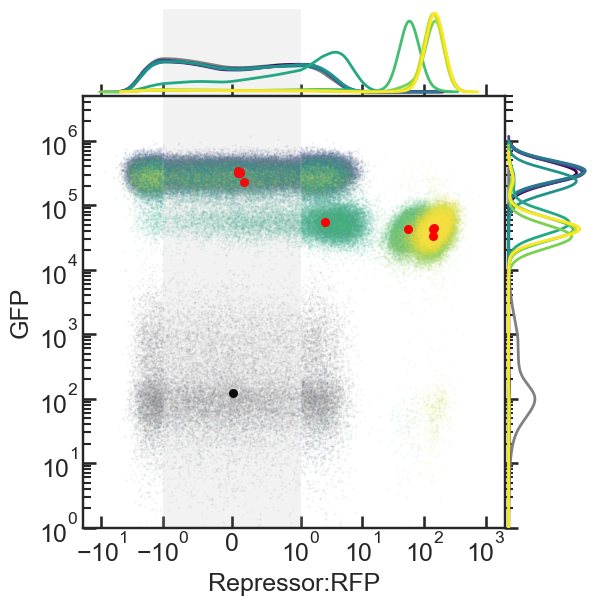

g2, M9, Rep 2


<Figure size 400x400 with 0 Axes>

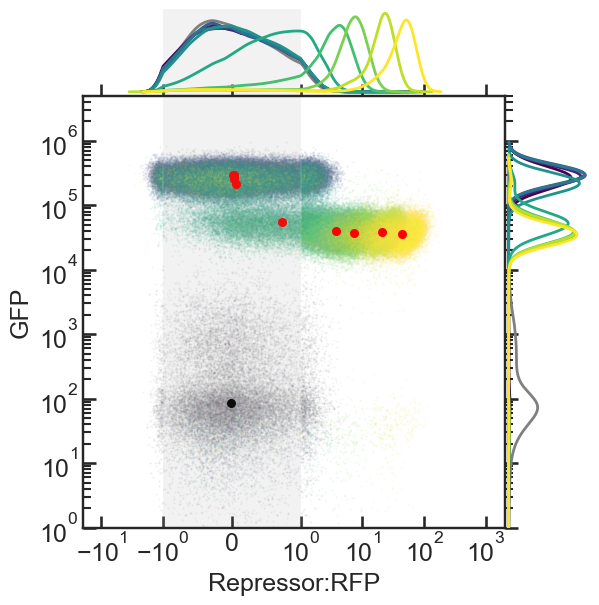

g2, M9, Rep 3


<Figure size 400x400 with 0 Axes>

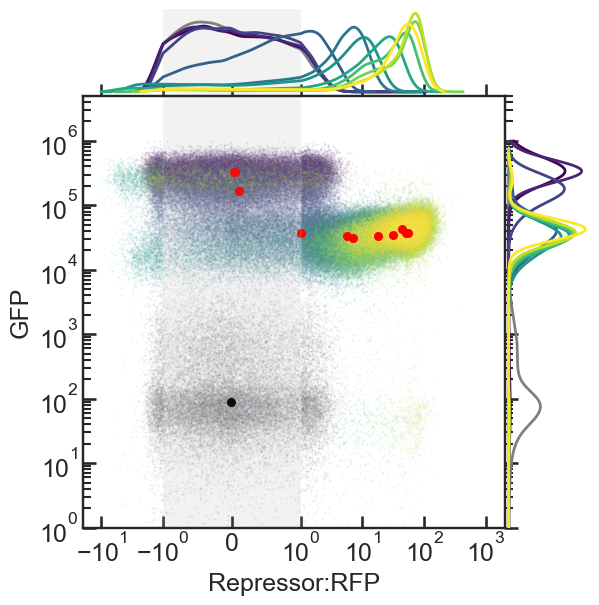

g2, CL, Rep 1


<Figure size 400x400 with 0 Axes>

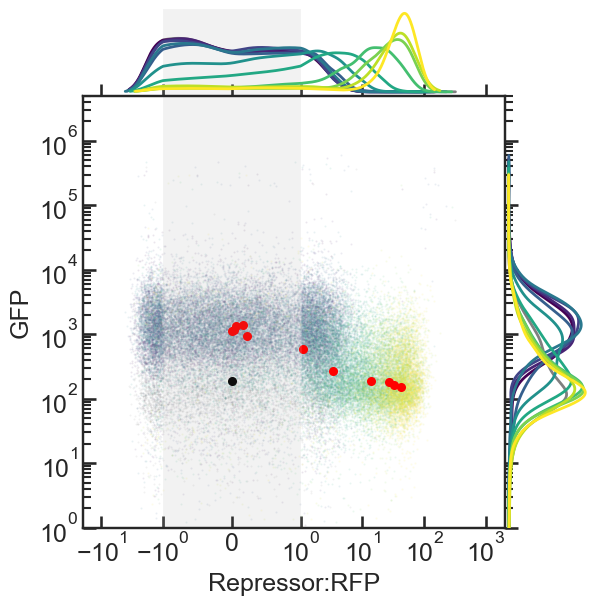

g2, CL, Rep 2


<Figure size 400x400 with 0 Axes>

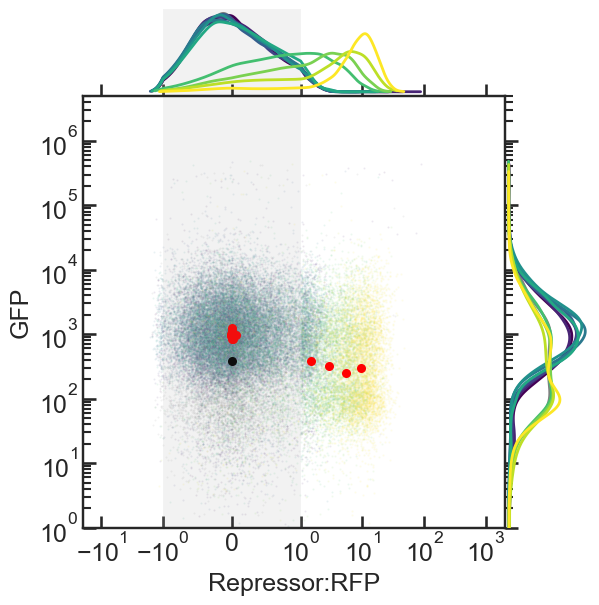

g2, CL, Rep 3


<Figure size 400x400 with 0 Axes>

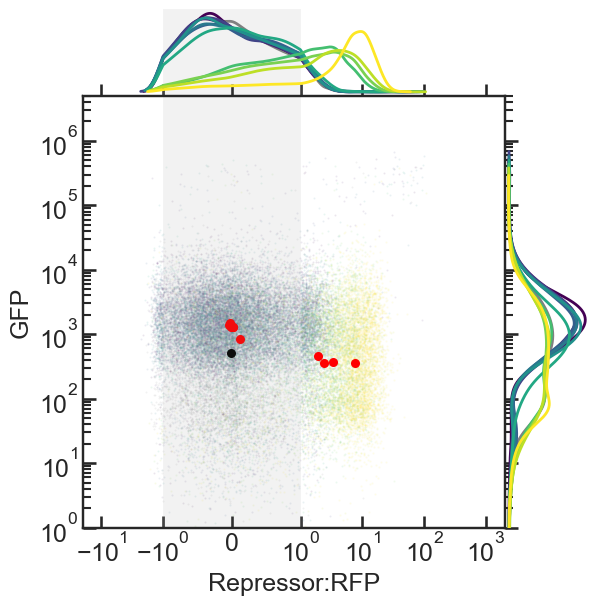

g3, M9, Rep 1


<Figure size 400x400 with 0 Axes>

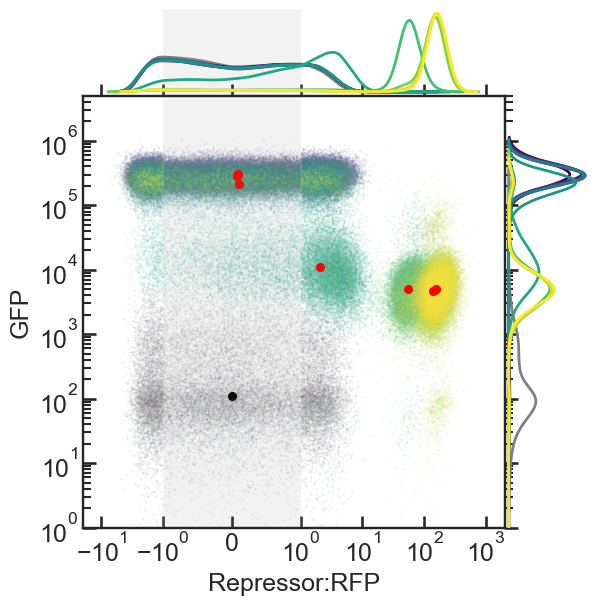

g3, M9, Rep 2


<Figure size 400x400 with 0 Axes>

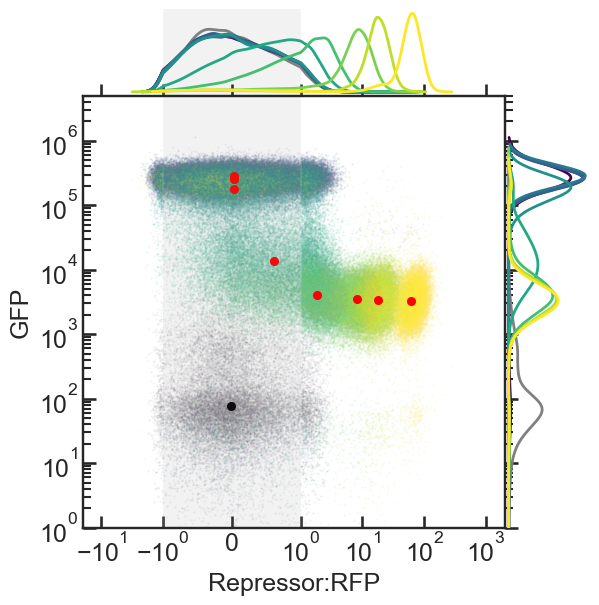

g3, M9, Rep 3


<Figure size 400x400 with 0 Axes>

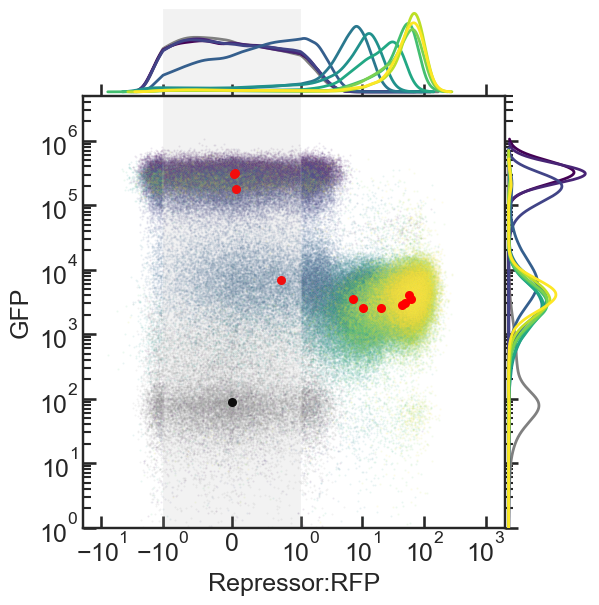

g3, CL, Rep 1


<Figure size 400x400 with 0 Axes>

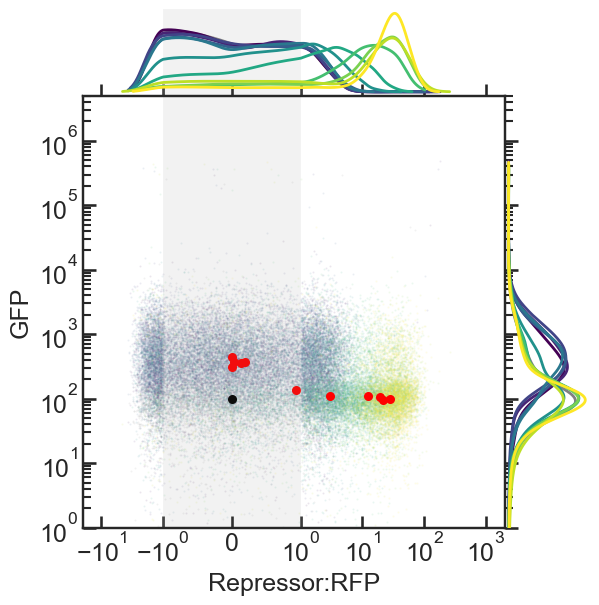

g3, CL, Rep 2


<Figure size 400x400 with 0 Axes>

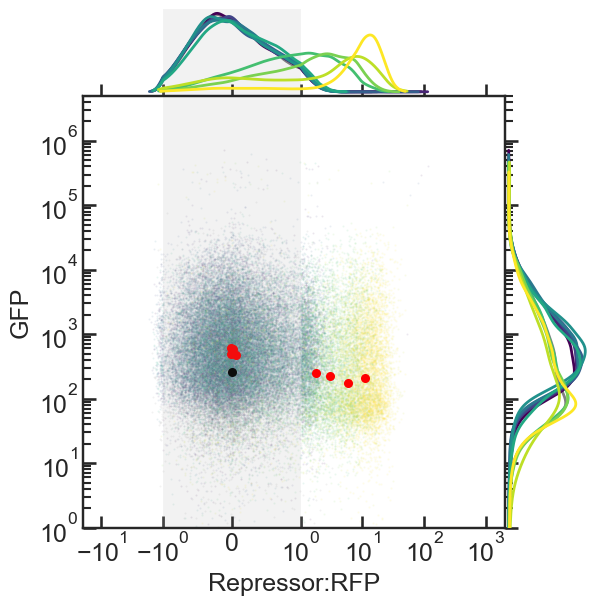

g3, CL, Rep 3


<Figure size 400x400 with 0 Axes>

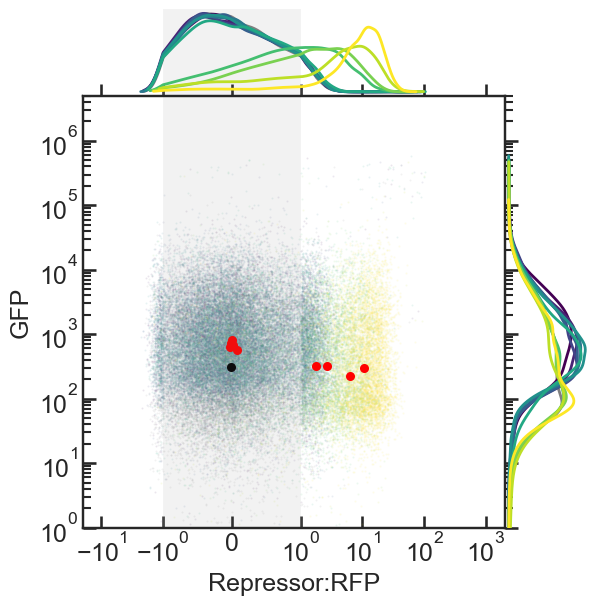

g4, M9, Rep 1


<Figure size 400x400 with 0 Axes>

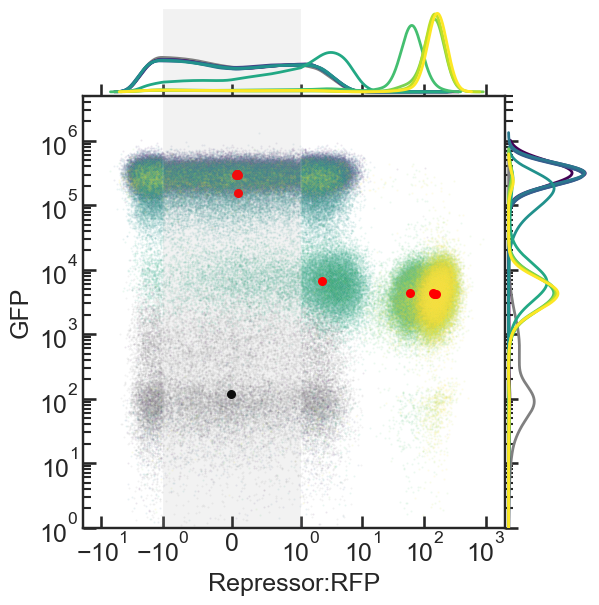

g4, M9, Rep 2


<Figure size 400x400 with 0 Axes>

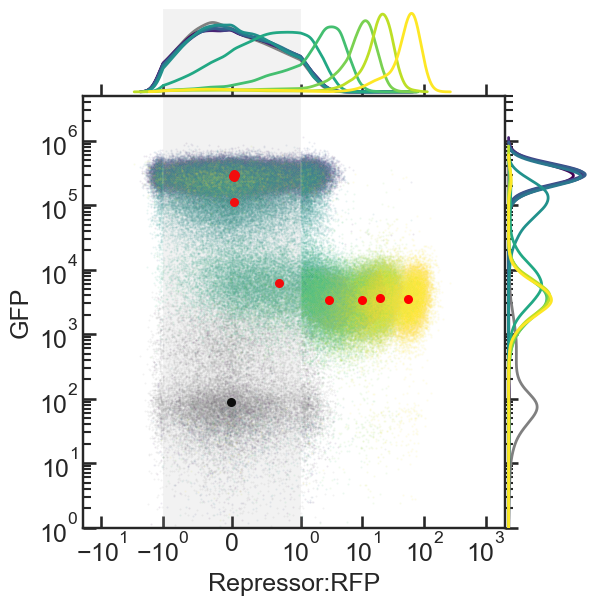

g4, M9, Rep 3


<Figure size 400x400 with 0 Axes>

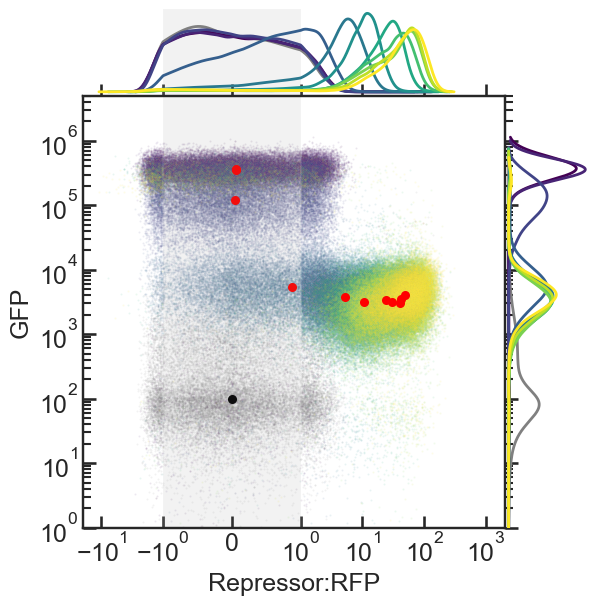

g4, CL, Rep 1


<Figure size 400x400 with 0 Axes>

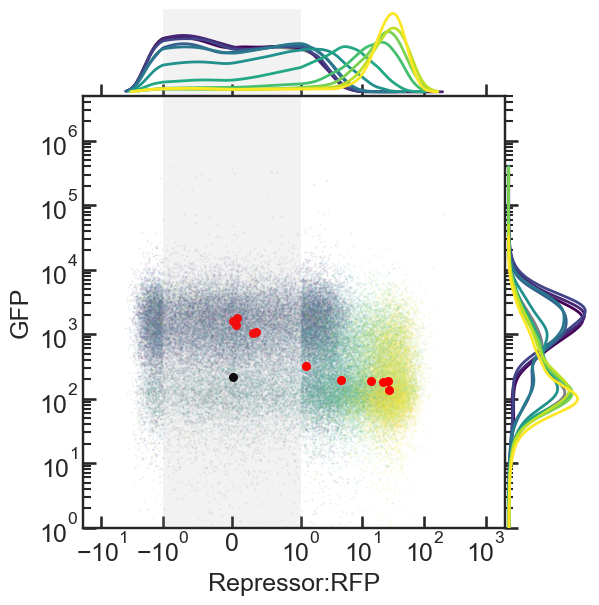

g4, CL, Rep 2


<Figure size 400x400 with 0 Axes>

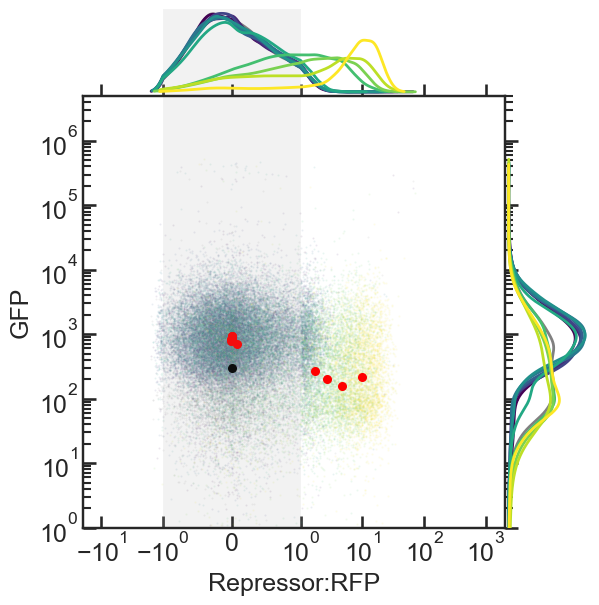

g4, CL, Rep 3


<Figure size 400x400 with 0 Axes>

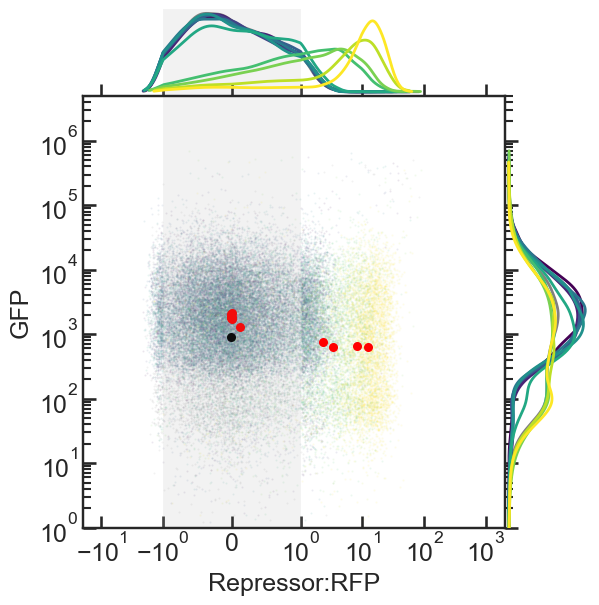

g5, M9, Rep 1


<Figure size 400x400 with 0 Axes>

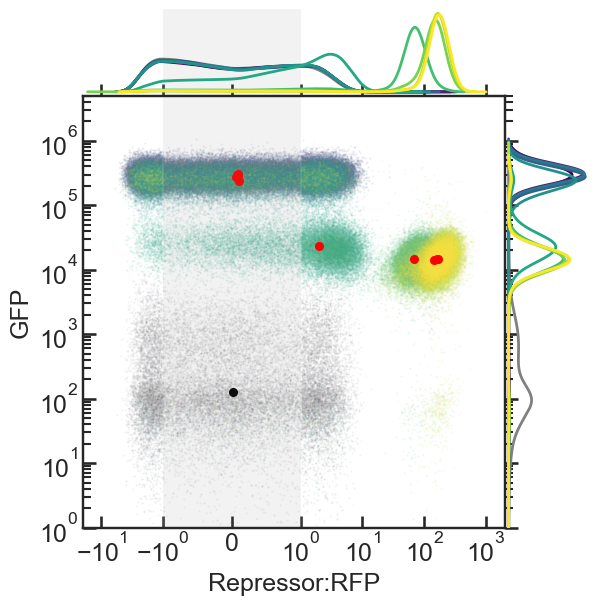

g5, M9, Rep 2


<Figure size 400x400 with 0 Axes>

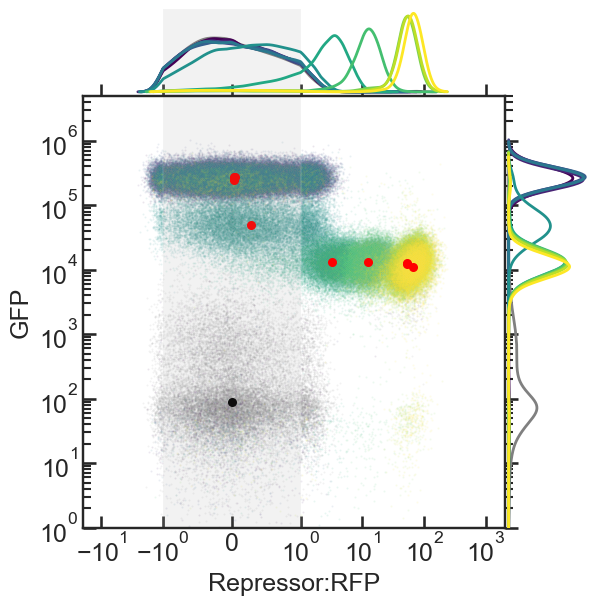

g5, M9, Rep 3


<Figure size 400x400 with 0 Axes>

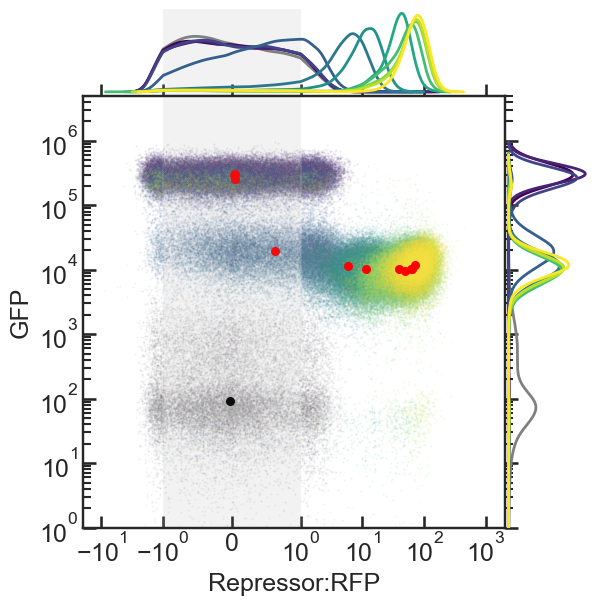

g5, CL, Rep 1


<Figure size 400x400 with 0 Axes>

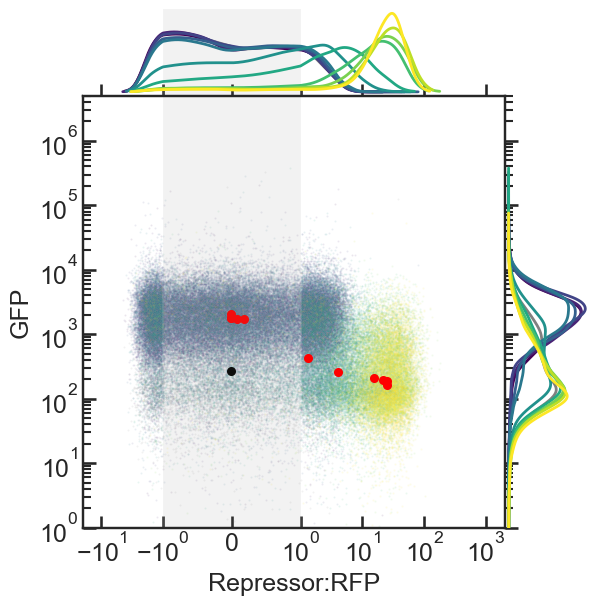

g5, CL, Rep 2


<Figure size 400x400 with 0 Axes>

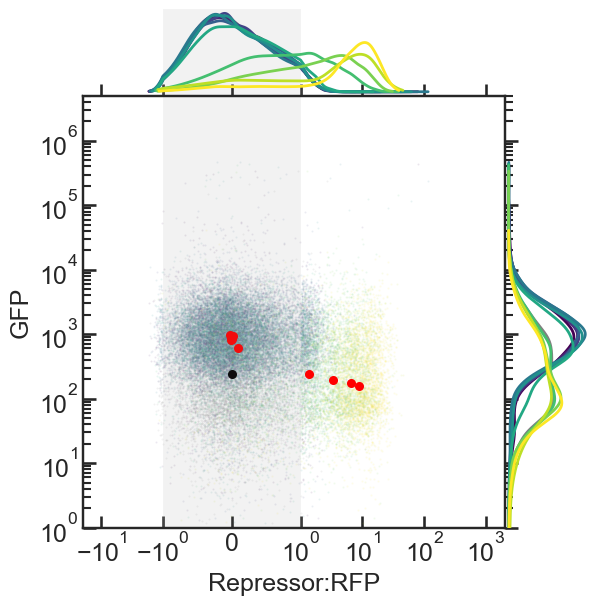

g5, CL, Rep 3


<Figure size 400x400 with 0 Axes>

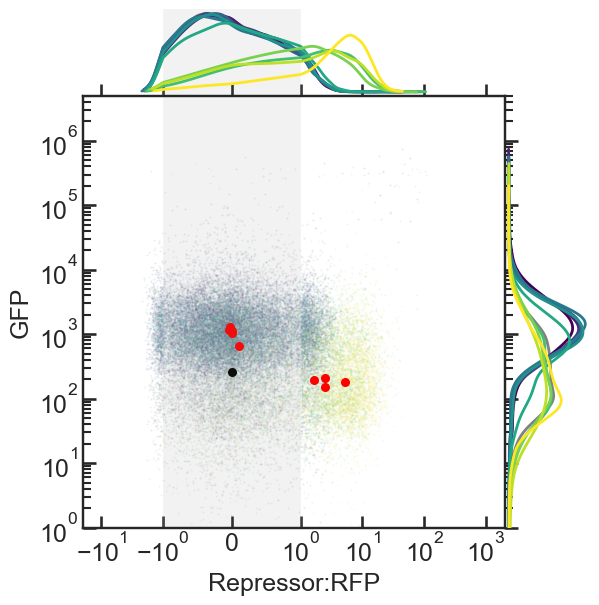

g6, M9, Rep 1


<Figure size 400x400 with 0 Axes>

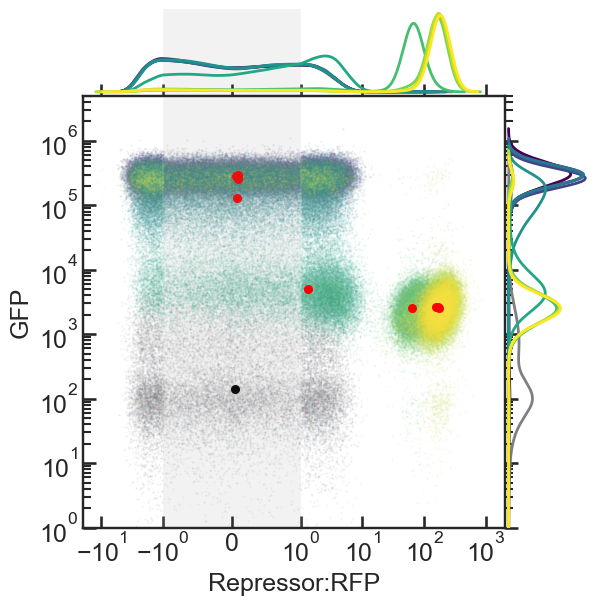

g6, M9, Rep 2


<Figure size 400x400 with 0 Axes>

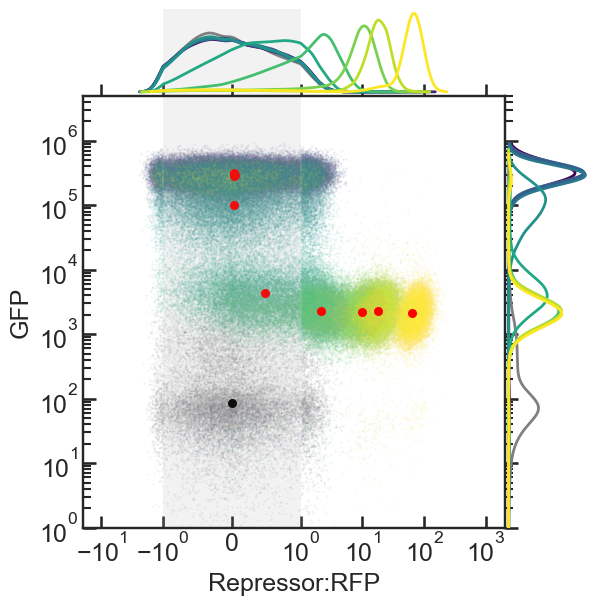

g6, M9, Rep 3


<Figure size 400x400 with 0 Axes>

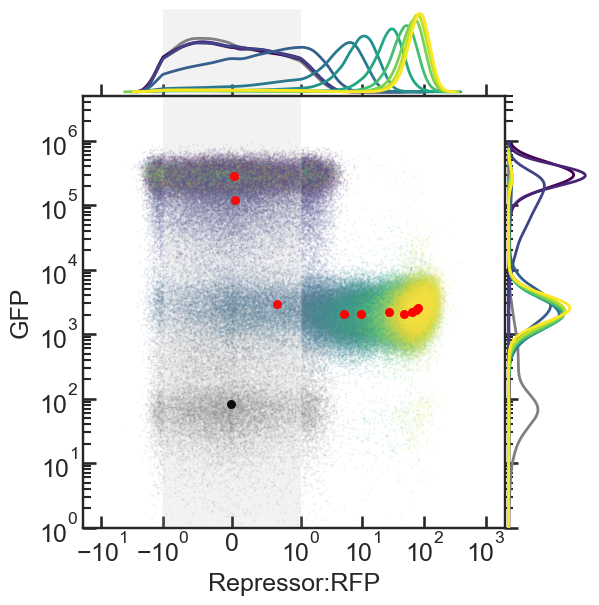

g6, CL, Rep 1


<Figure size 400x400 with 0 Axes>

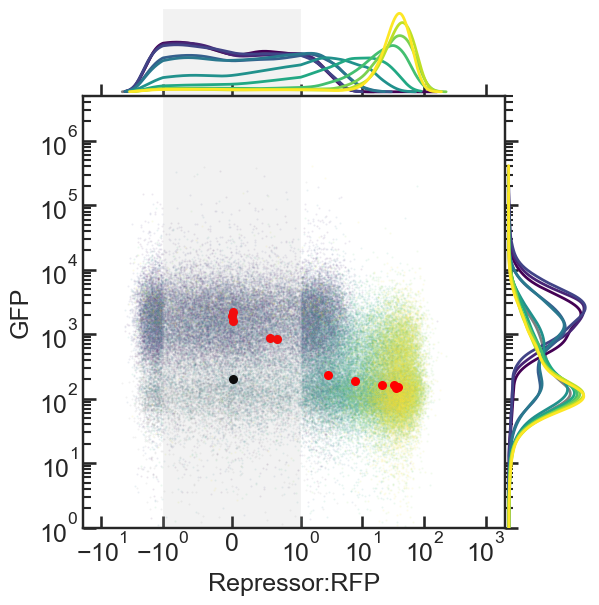

g6, CL, Rep 2


<Figure size 400x400 with 0 Axes>

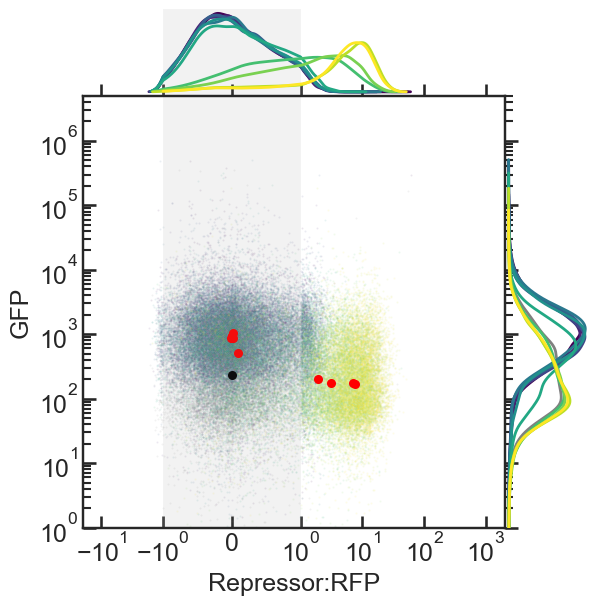

g6, CL, Rep 3


<Figure size 400x400 with 0 Axes>

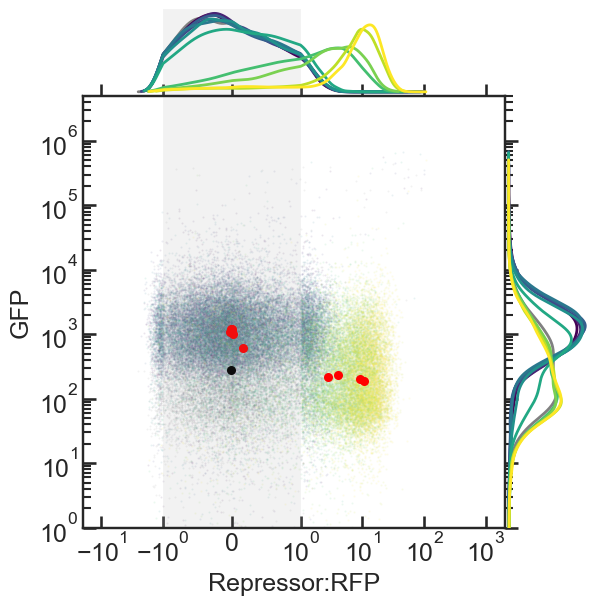

g8, M9, Rep 1


<Figure size 400x400 with 0 Axes>

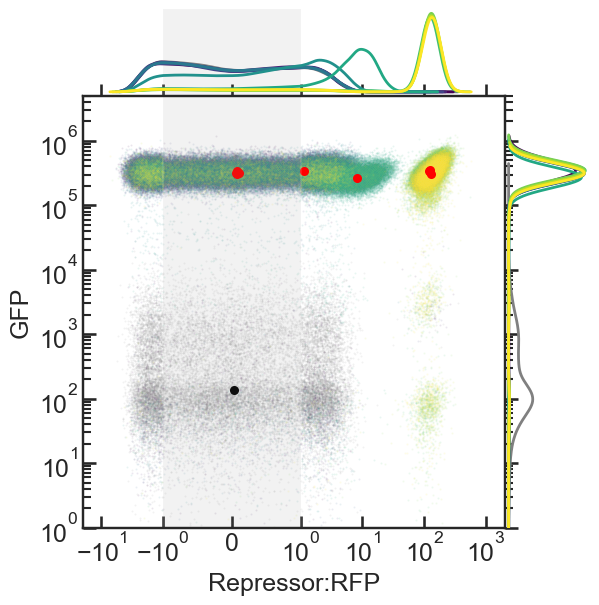

g8, M9, Rep 2


<Figure size 400x400 with 0 Axes>

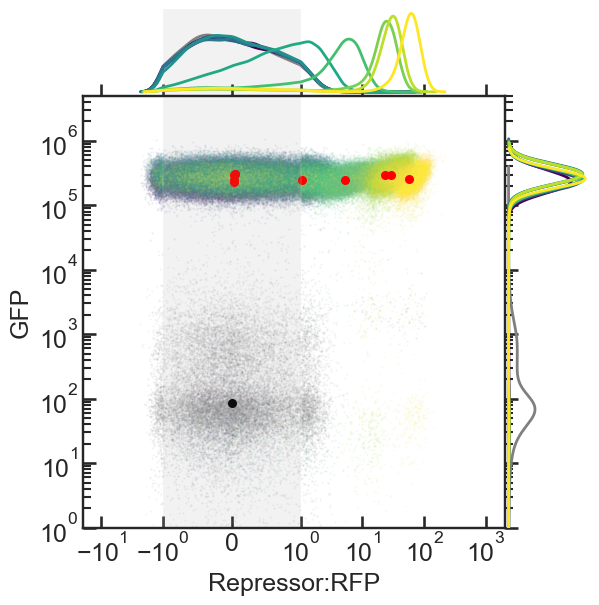

g8, M9, Rep 3


<Figure size 400x400 with 0 Axes>

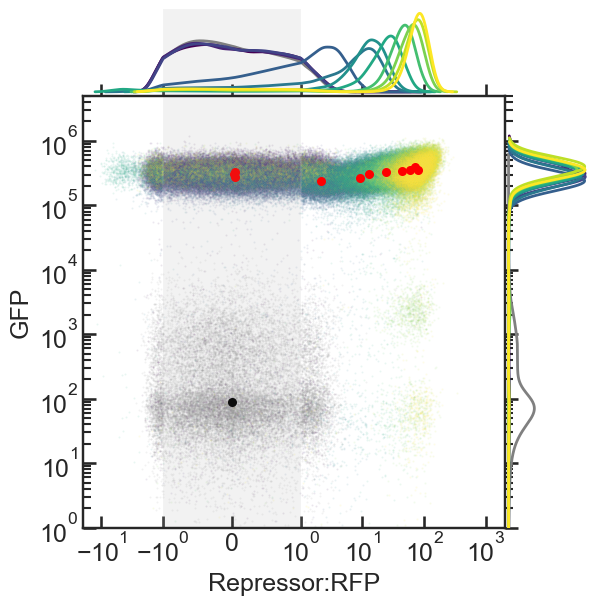

g8, CL, Rep 1


<Figure size 400x400 with 0 Axes>

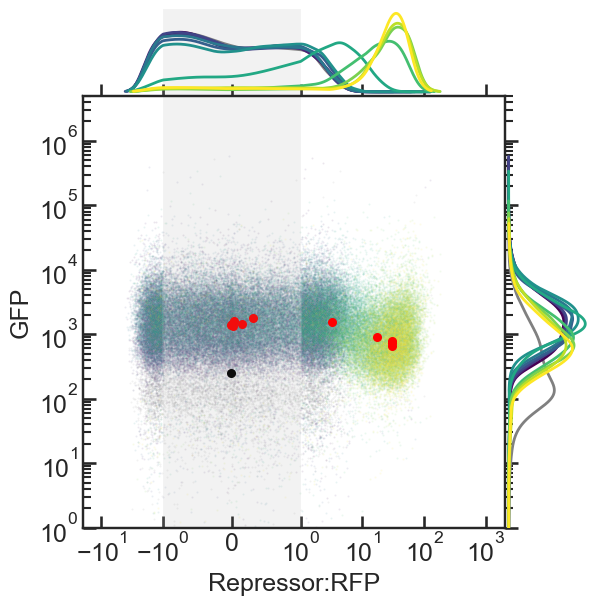

g8, CL, Rep 2


<Figure size 400x400 with 0 Axes>

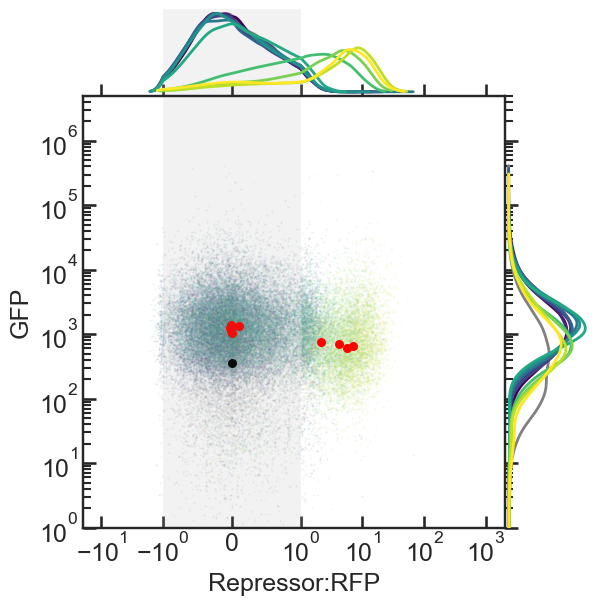

g8, CL, Rep 3


<Figure size 400x400 with 0 Axes>

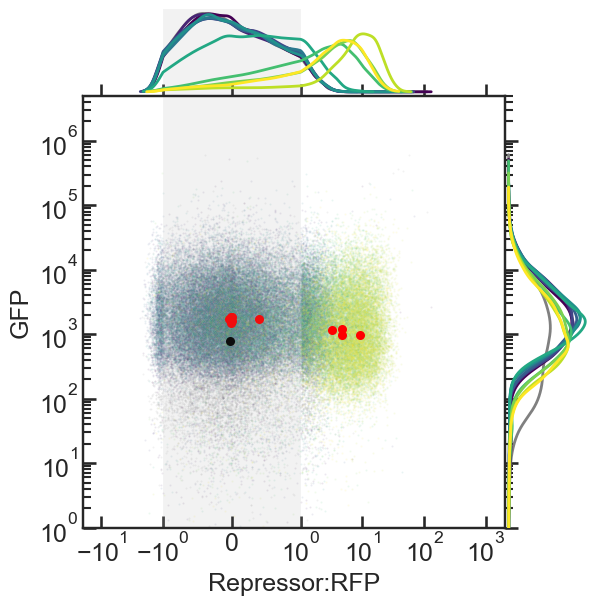

g9, M9, Rep 1


<Figure size 400x400 with 0 Axes>

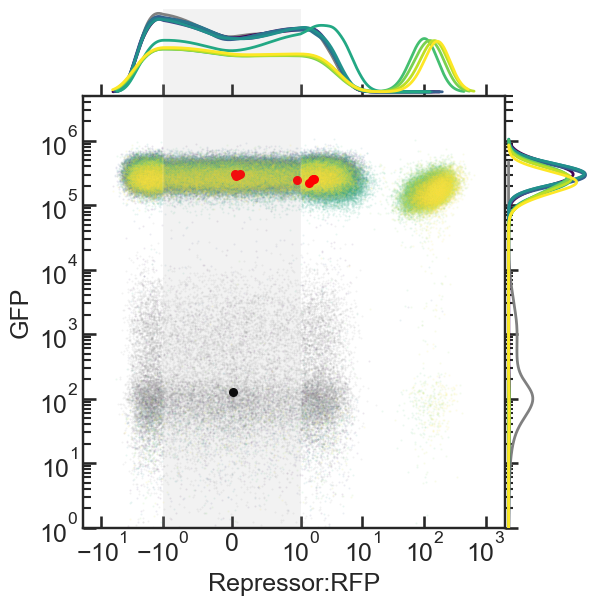

g9, M9, Rep 2


<Figure size 400x400 with 0 Axes>

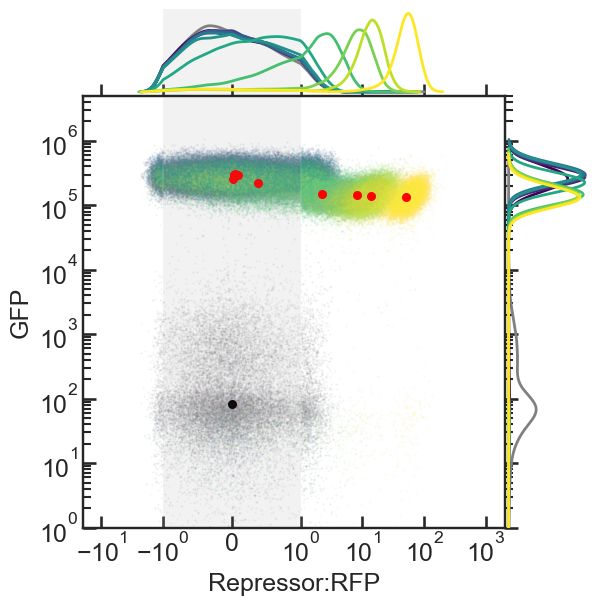

g9, M9, Rep 3


<Figure size 400x400 with 0 Axes>

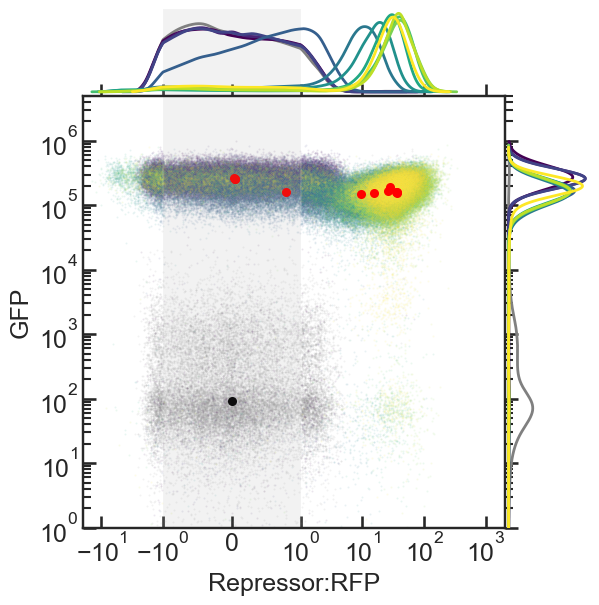

g9, CL, Rep 1


<Figure size 400x400 with 0 Axes>

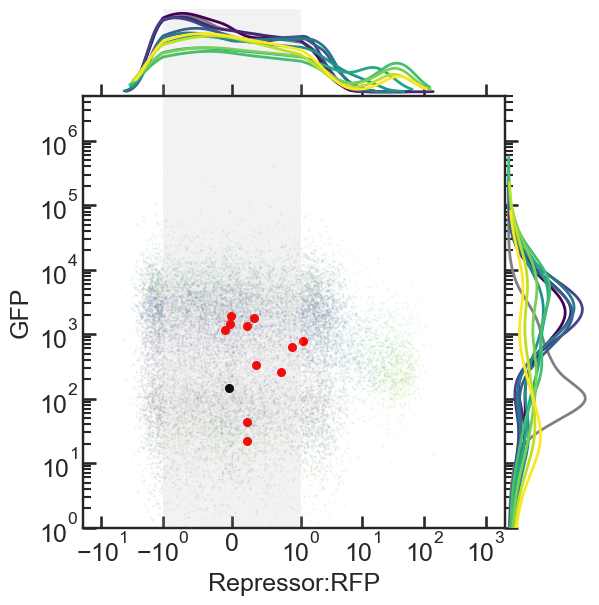

g9, CL, Rep 2


<Figure size 400x400 with 0 Axes>

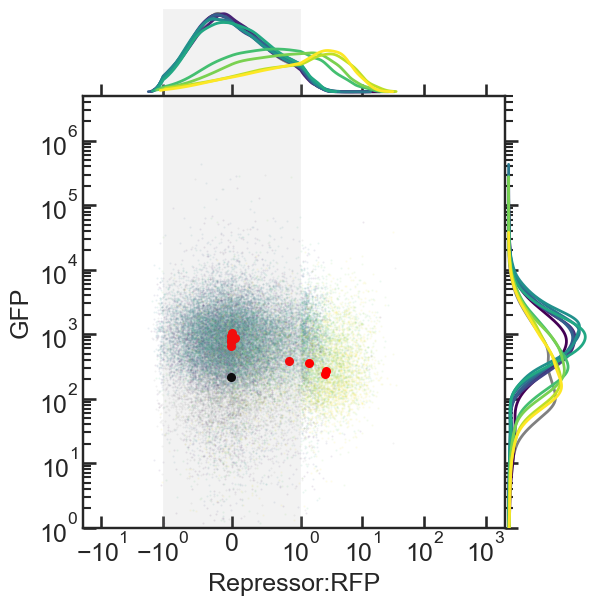

g9, CL, Rep 3


<Figure size 400x400 with 0 Axes>

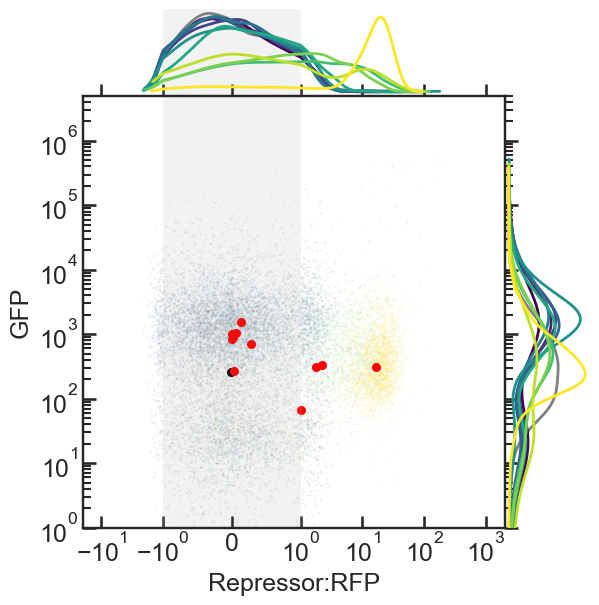

g10, M9, Rep 1


<Figure size 400x400 with 0 Axes>

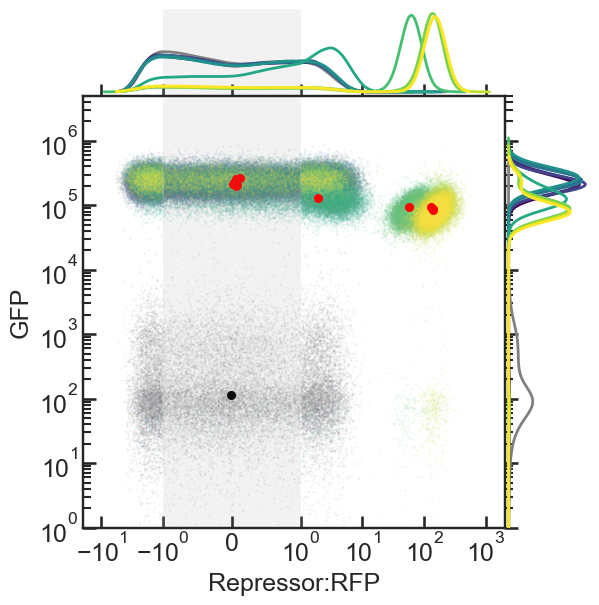

g10, M9, Rep 2


<Figure size 400x400 with 0 Axes>

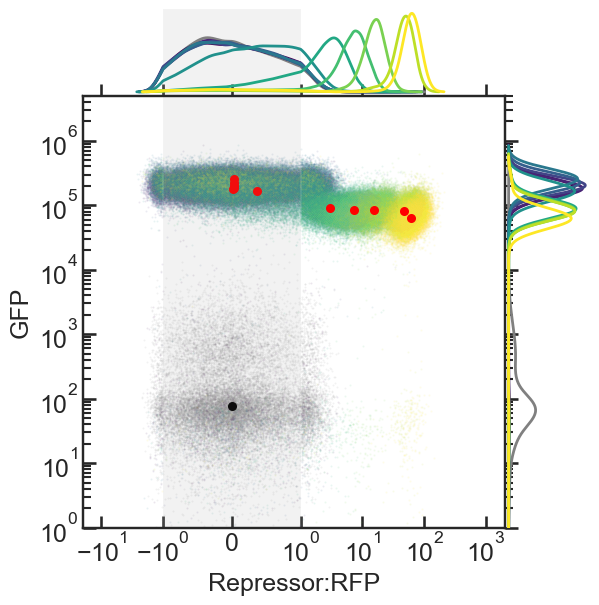

g10, M9, Rep 3


<Figure size 400x400 with 0 Axes>

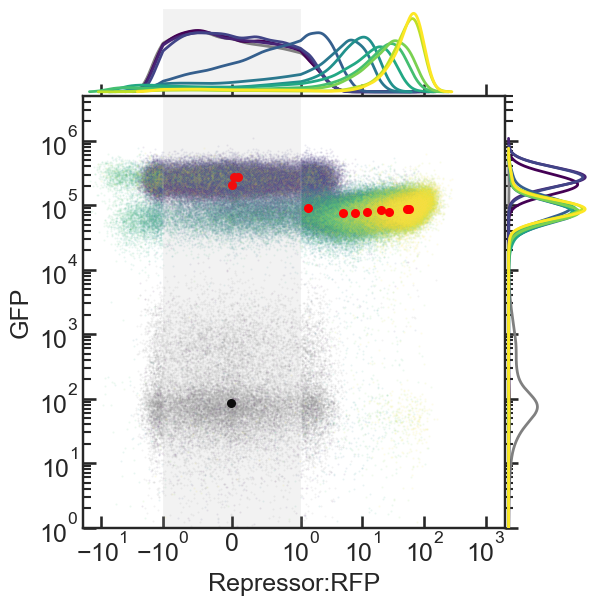

g10, CL, Rep 1


<Figure size 400x400 with 0 Axes>

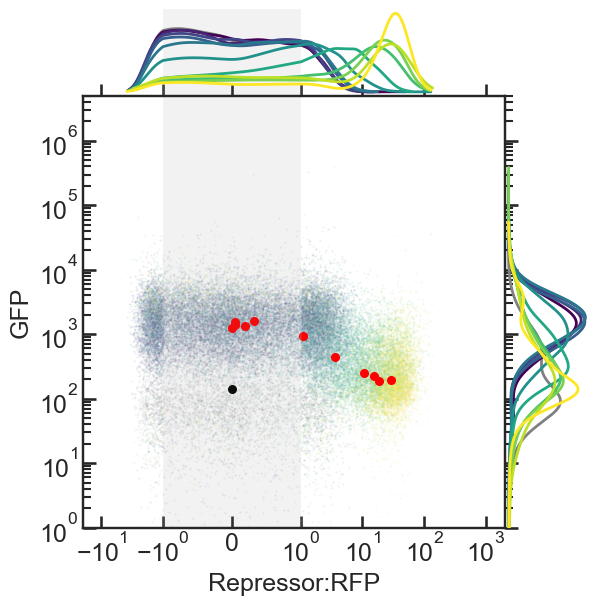

g10, CL, Rep 2


<Figure size 400x400 with 0 Axes>

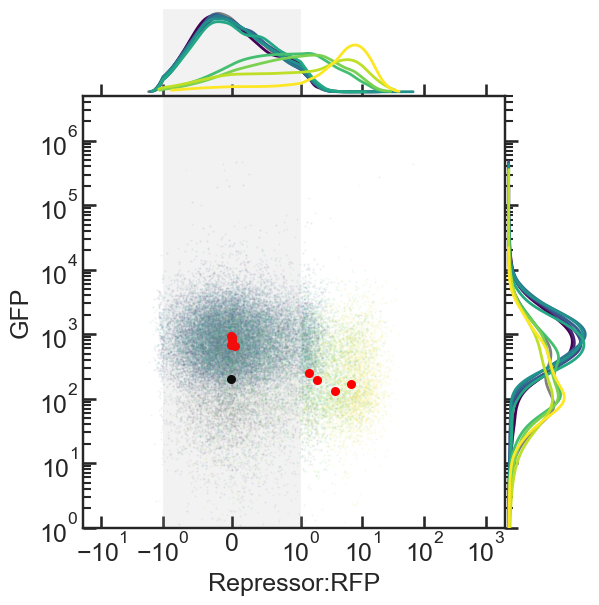

g10, CL, Rep 3


<Figure size 400x400 with 0 Axes>

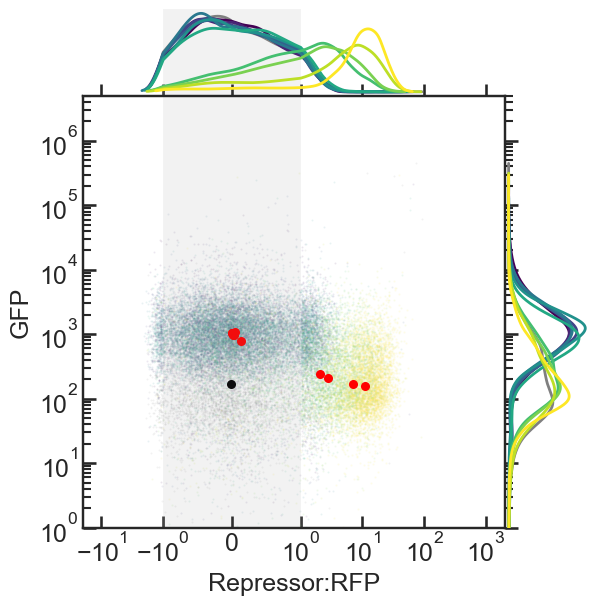

g11, M9, Rep 1


<Figure size 400x400 with 0 Axes>

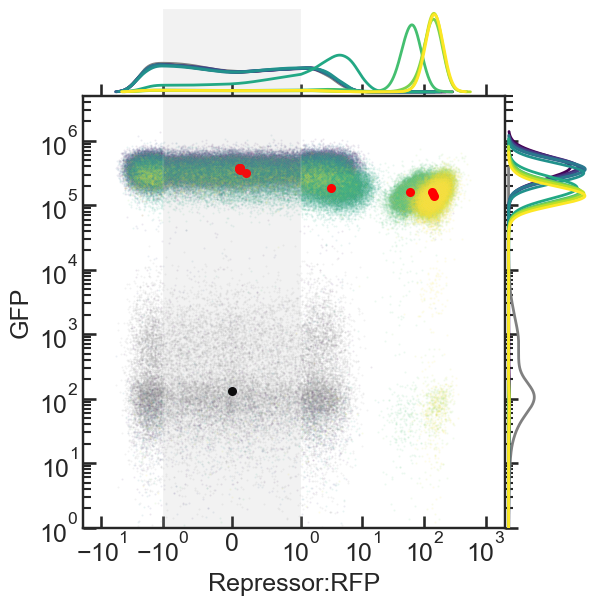

g11, M9, Rep 2


<Figure size 400x400 with 0 Axes>

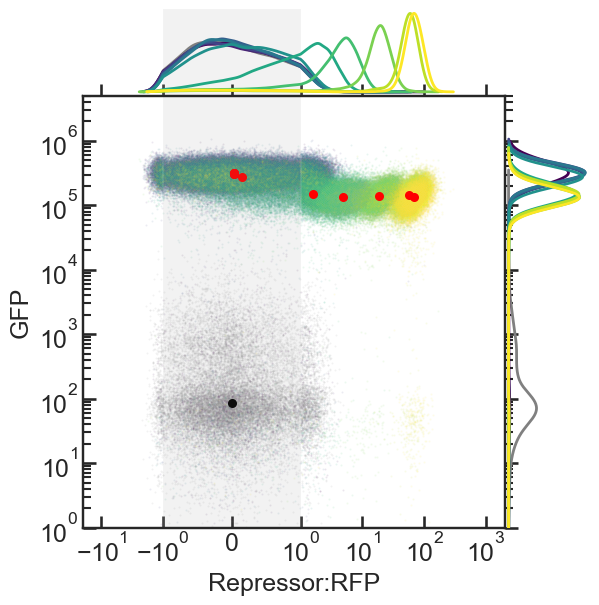

g11, M9, Rep 3


<Figure size 400x400 with 0 Axes>

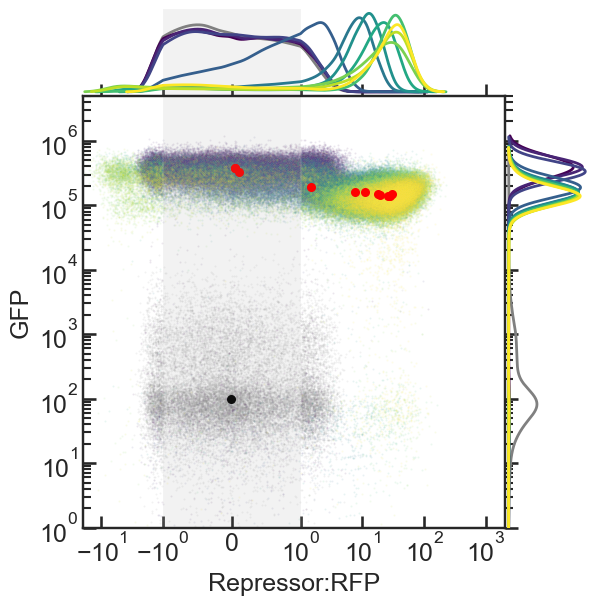

g11, CL, Rep 1


<Figure size 400x400 with 0 Axes>

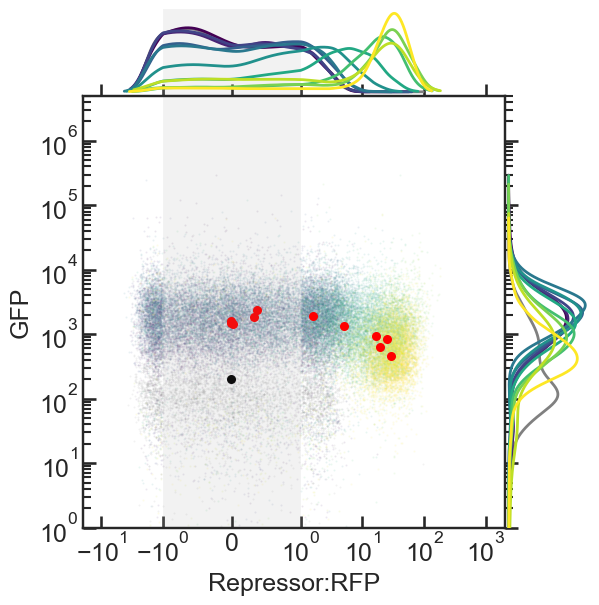

g11, CL, Rep 2


<Figure size 400x400 with 0 Axes>

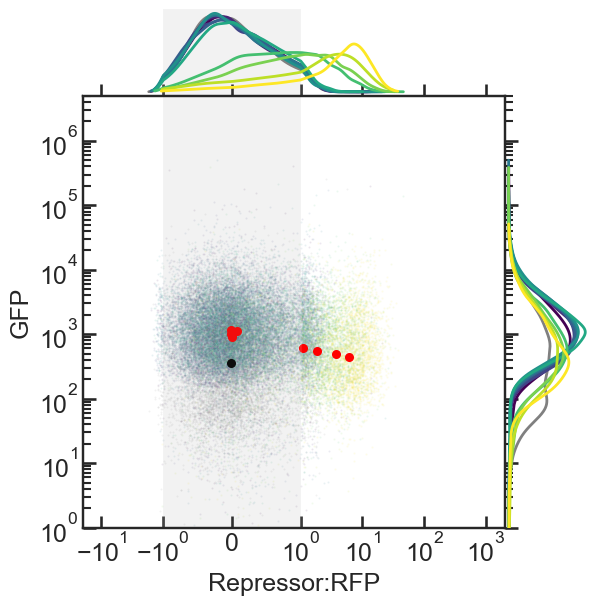

g11, CL, Rep 3


<Figure size 400x400 with 0 Axes>

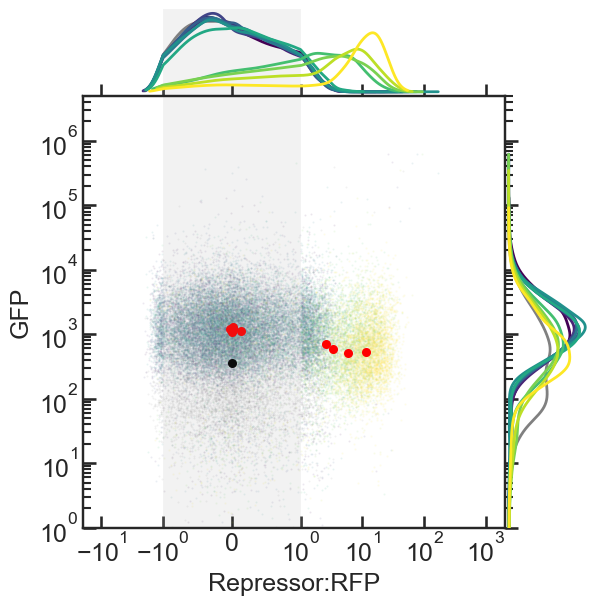

g12, M9, Rep 1


<Figure size 400x400 with 0 Axes>

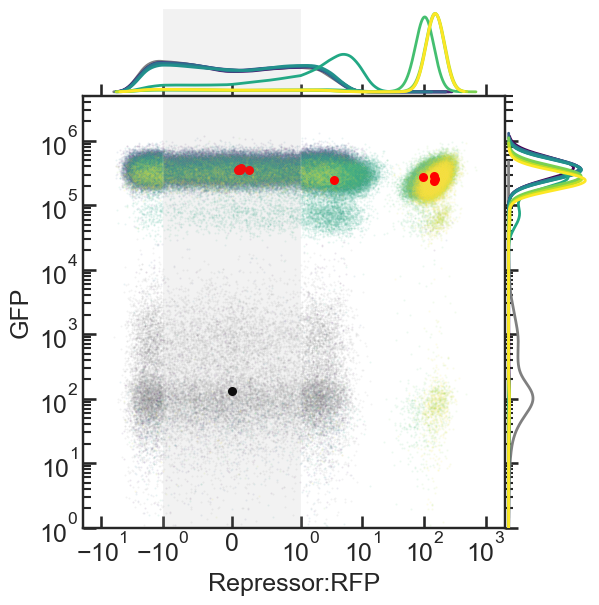

g12, M9, Rep 2


<Figure size 400x400 with 0 Axes>

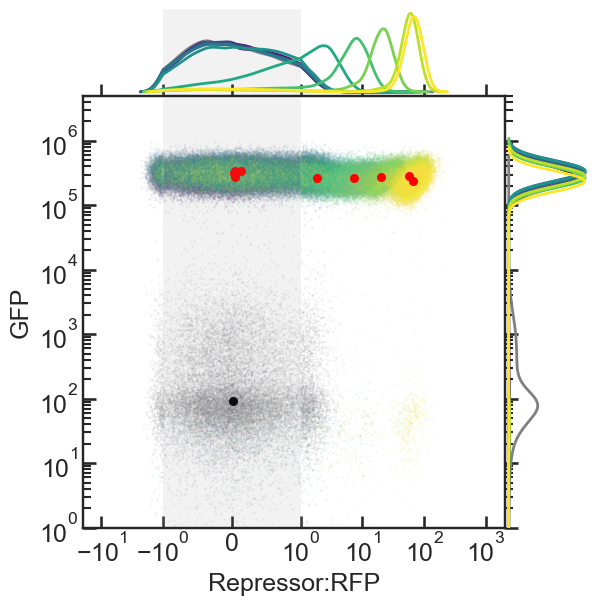

g12, M9, Rep 3


<Figure size 400x400 with 0 Axes>

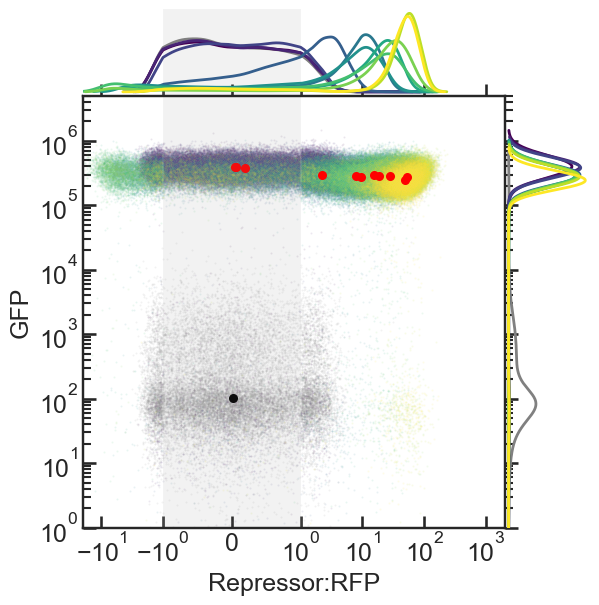

g12, CL, Rep 1


<Figure size 400x400 with 0 Axes>

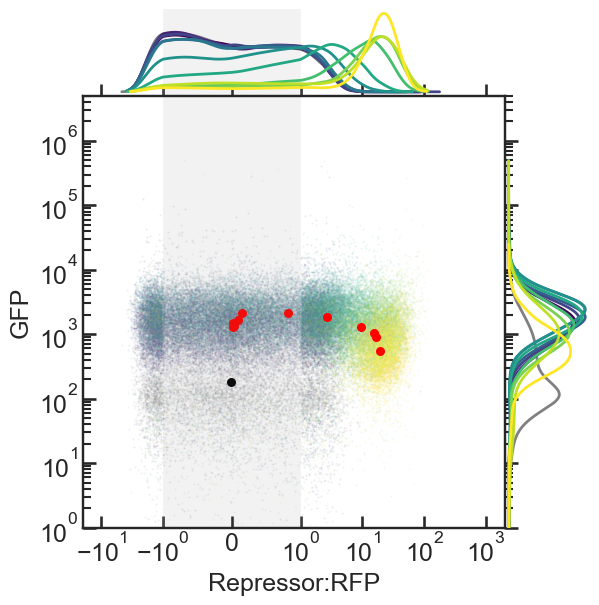

g12, CL, Rep 2


<Figure size 400x400 with 0 Axes>

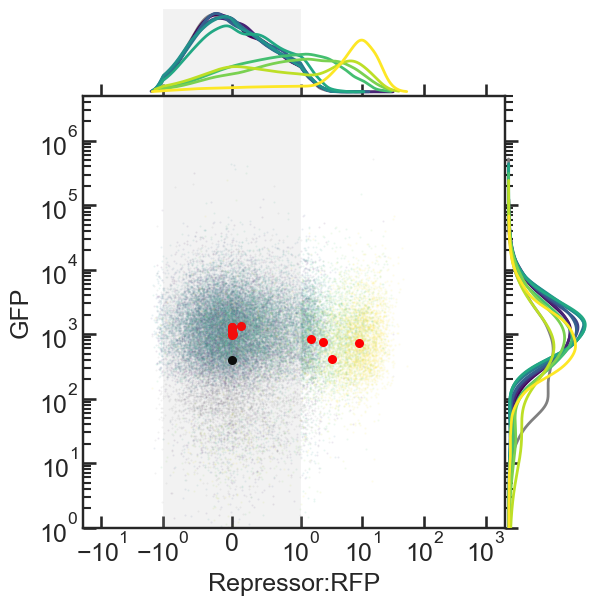

g12, CL, Rep 3


<Figure size 400x400 with 0 Axes>

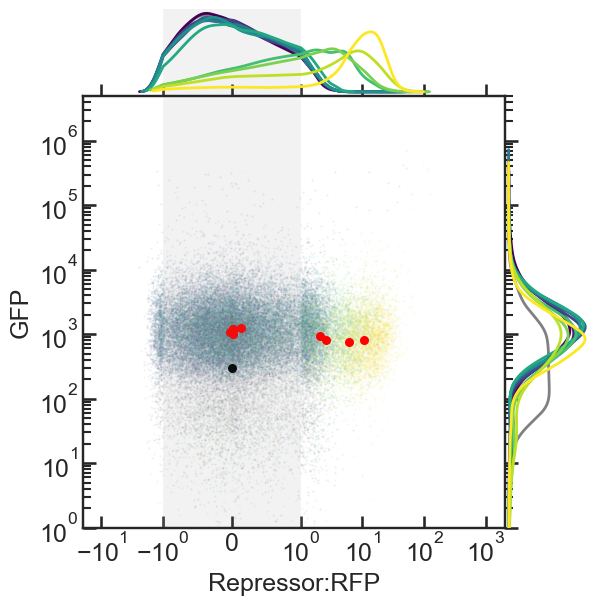

g13, M9, Rep 1


<Figure size 400x400 with 0 Axes>

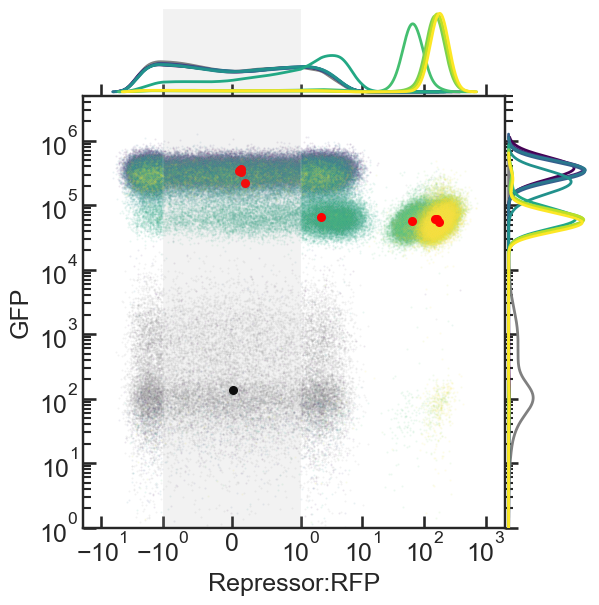

g13, M9, Rep 2


<Figure size 400x400 with 0 Axes>

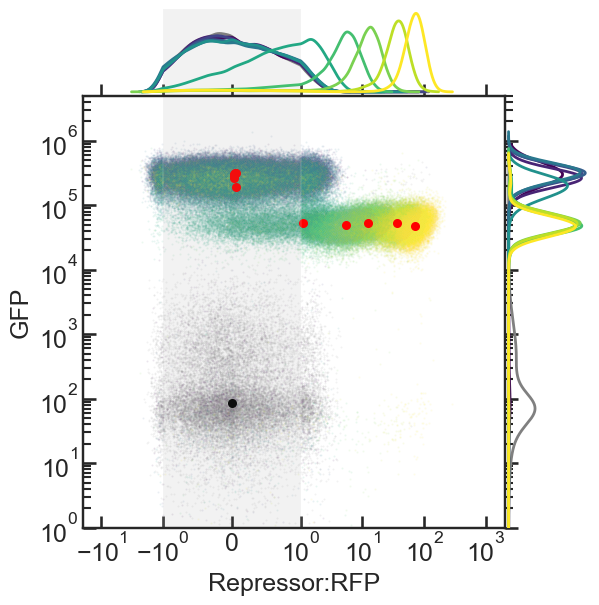

g13, M9, Rep 3


<Figure size 400x400 with 0 Axes>

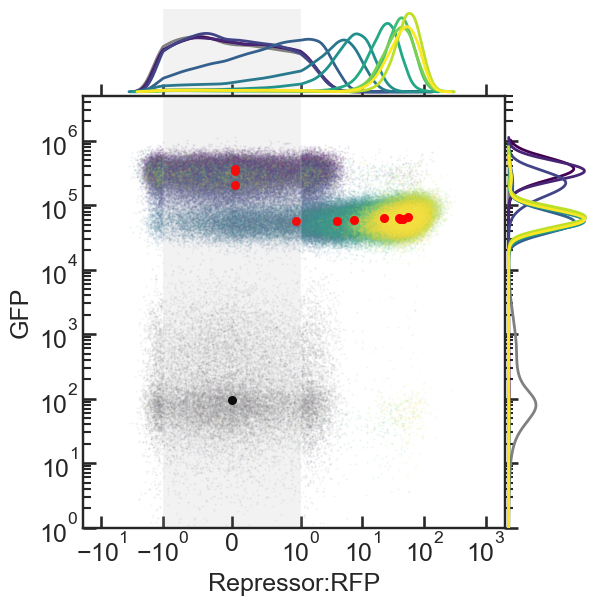

g13, CL, Rep 1


<Figure size 400x400 with 0 Axes>

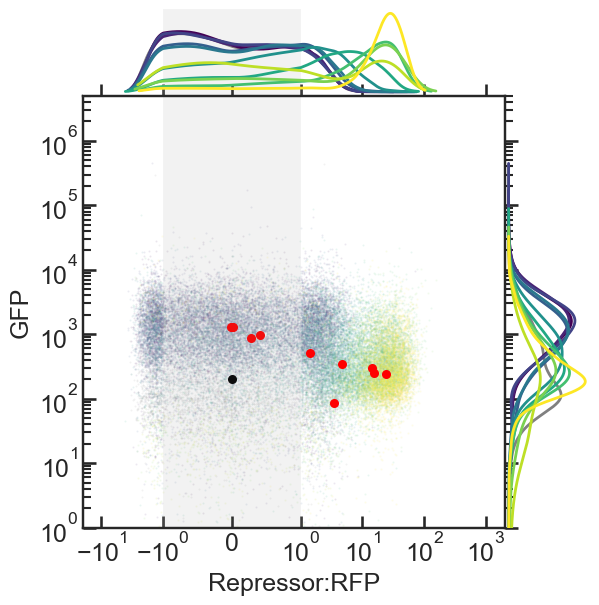

g13, CL, Rep 2


<Figure size 400x400 with 0 Axes>

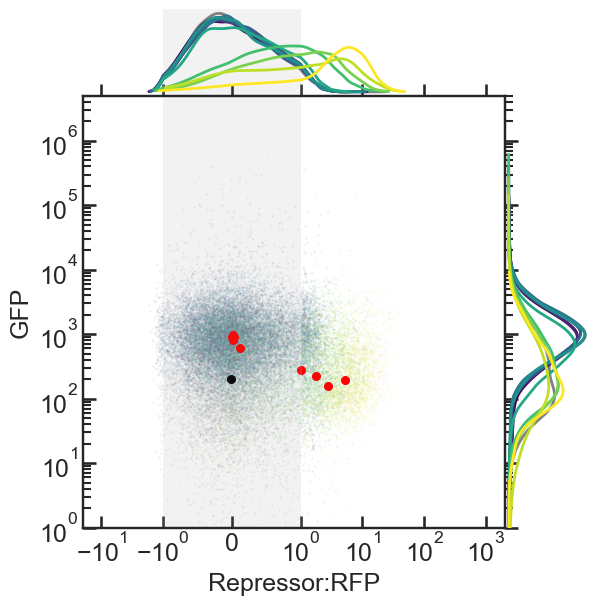

g13, CL, Rep 3


<Figure size 400x400 with 0 Axes>

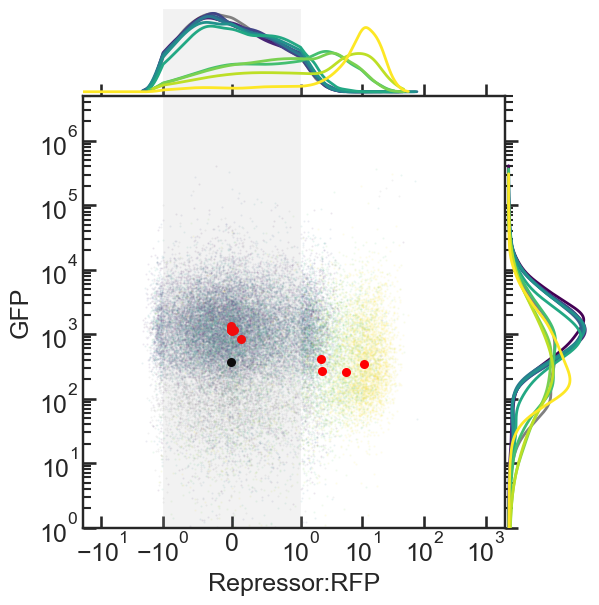

g14, M9, Rep 1


<Figure size 400x400 with 0 Axes>

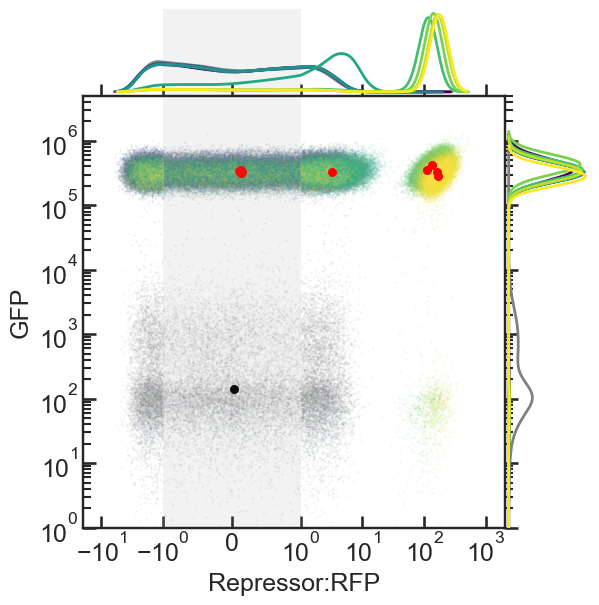

g14, M9, Rep 2


<Figure size 400x400 with 0 Axes>

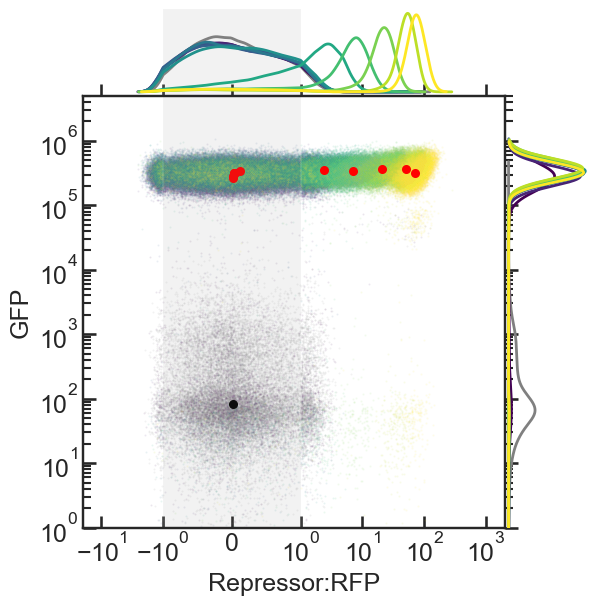

g14, M9, Rep 3


<Figure size 400x400 with 0 Axes>

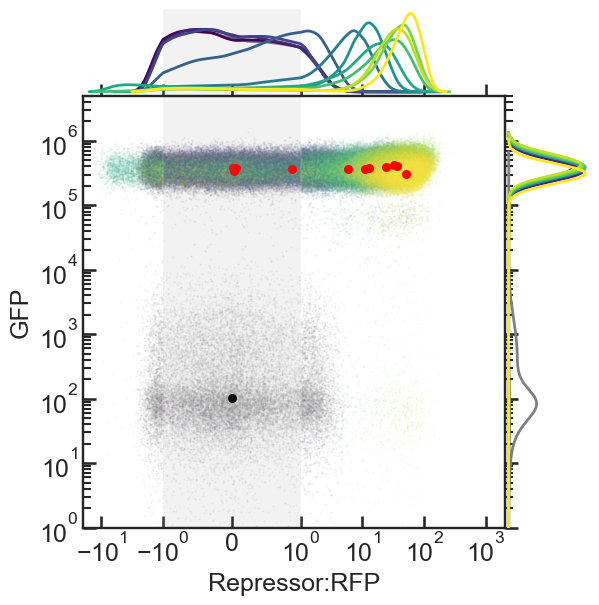

g14, CL, Rep 1


<Figure size 400x400 with 0 Axes>

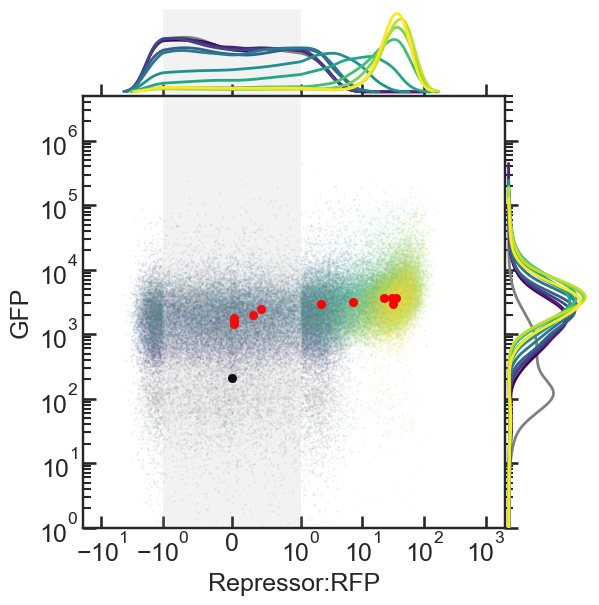

g14, CL, Rep 2


<Figure size 400x400 with 0 Axes>

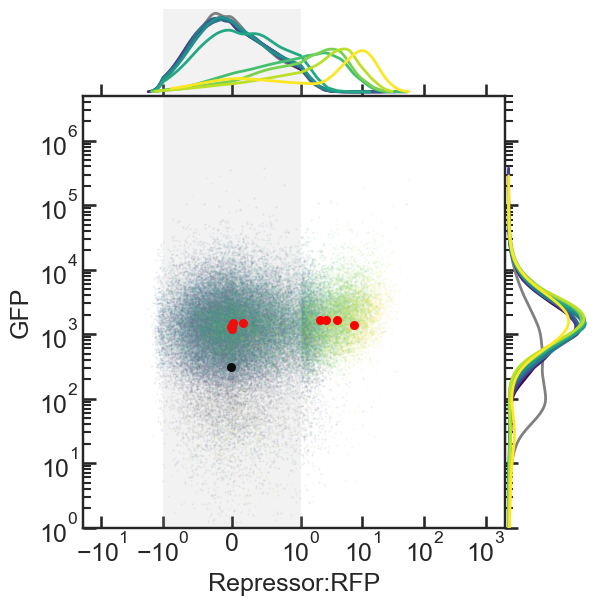

g14, CL, Rep 3


<Figure size 400x400 with 0 Axes>

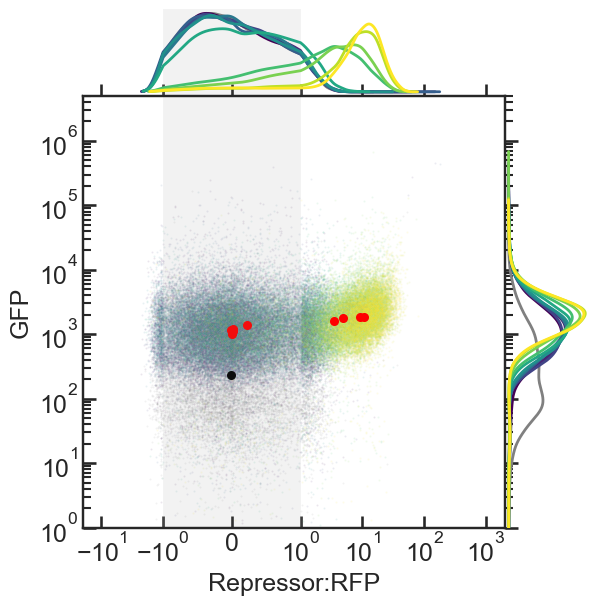

In [15]:
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, savefig=True, filetype='png')


## Plots of MCMC results

Supplemental Figs 1-13.

Requires prior pickling of MCMC runs.

In [10]:
# generate a dataframe of just median (RFP,GFP) values, grouping replicates
medias = ['M9', 'CL']

df_ls = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls.append(row_to_append)

        df_medians = pd.DataFrame(df_ls, columns=['gRNA','Media','ln median GFP', 'median RFP'])

g1


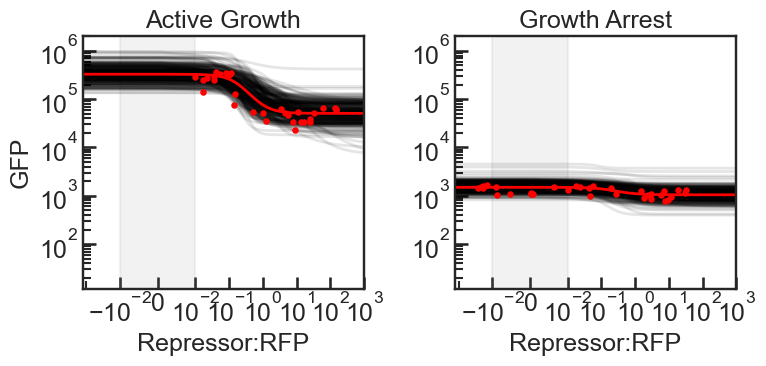

g2


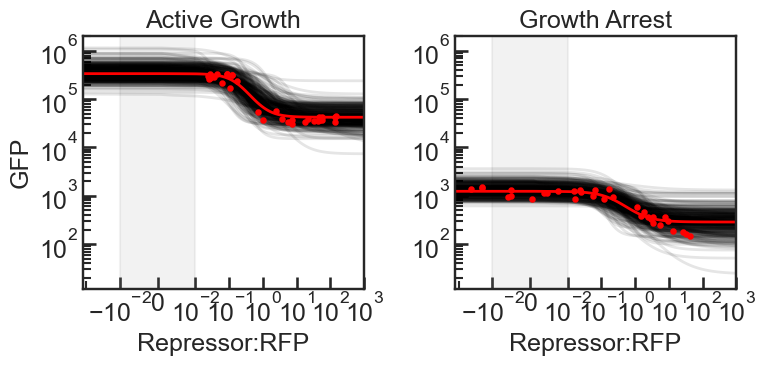

g3


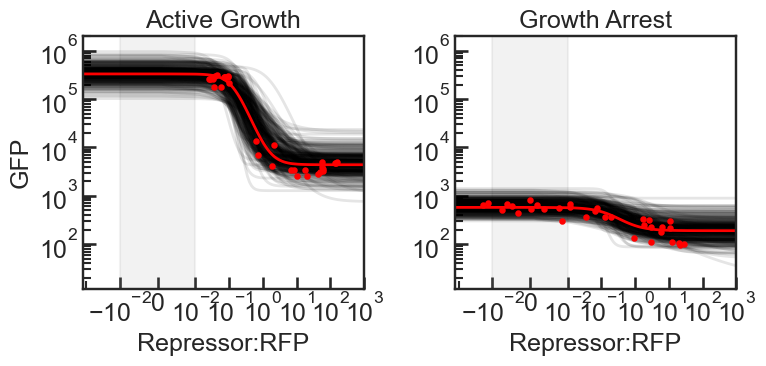

g4


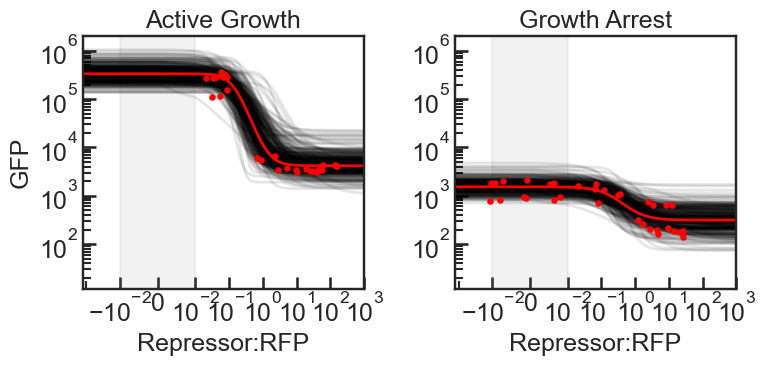

g5


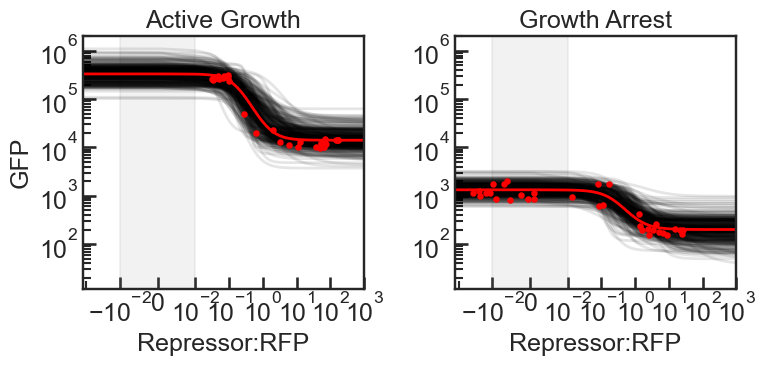

g6


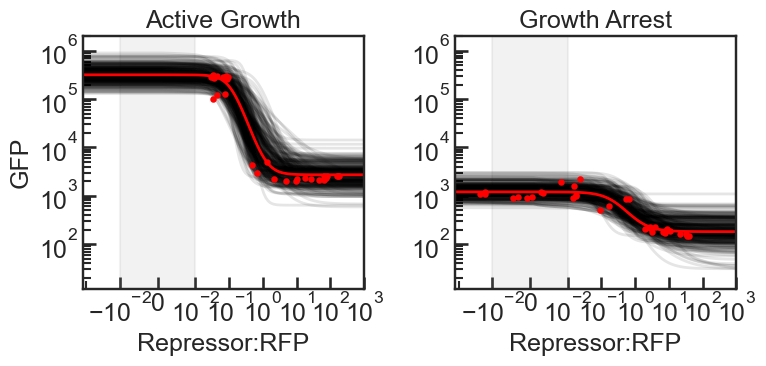

g8


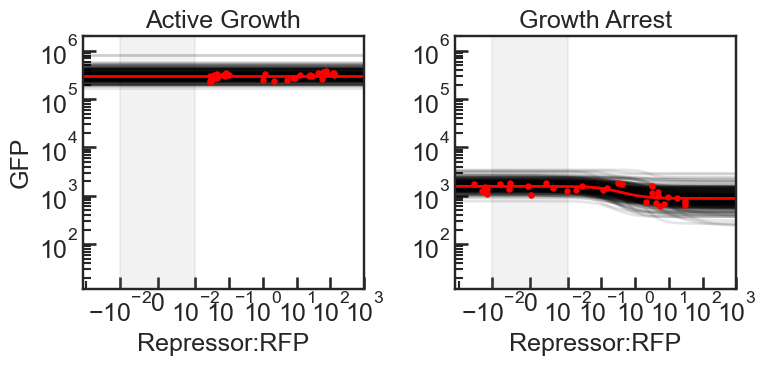

g9


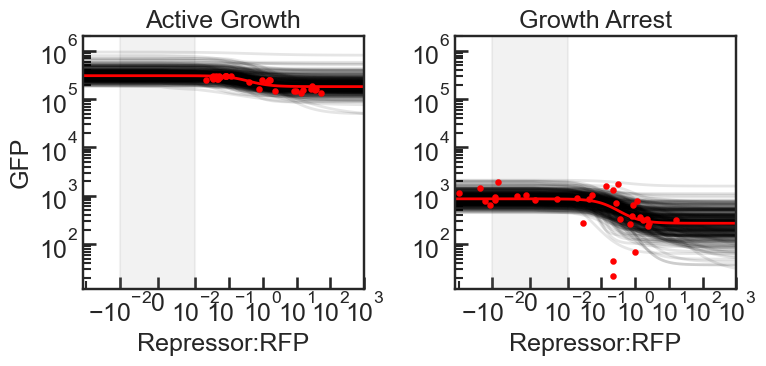

g10


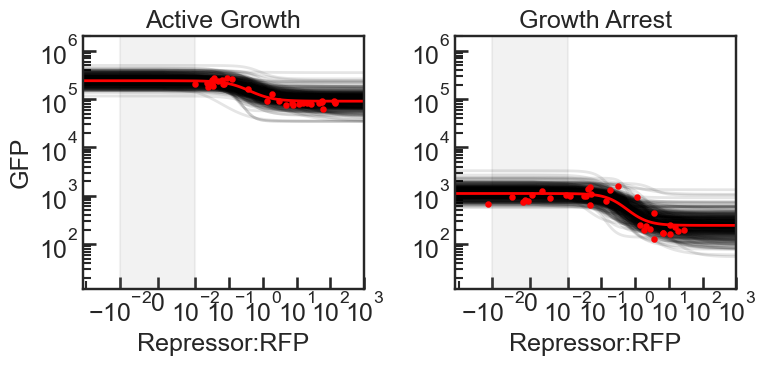

g11


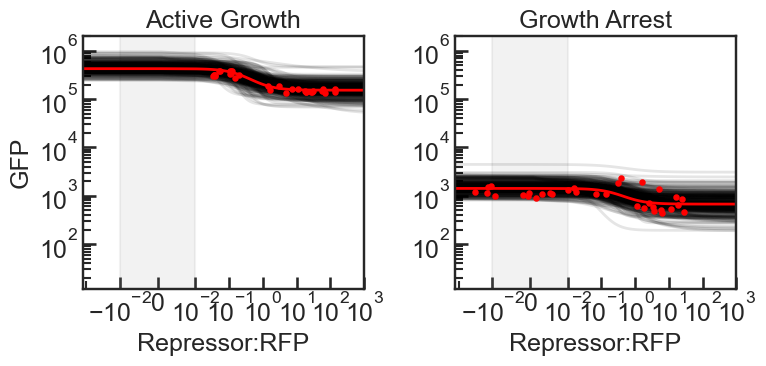

g12


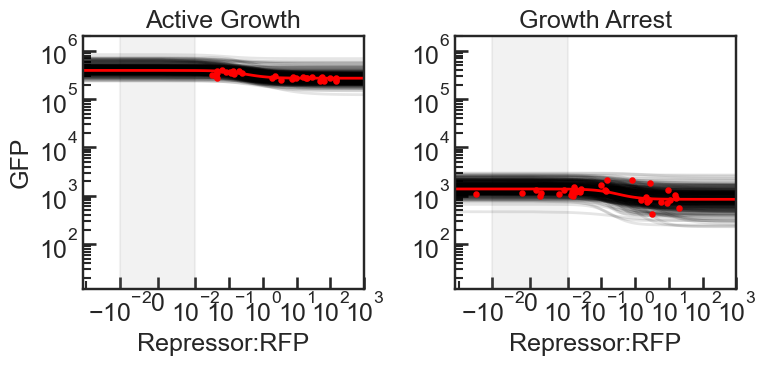

g13


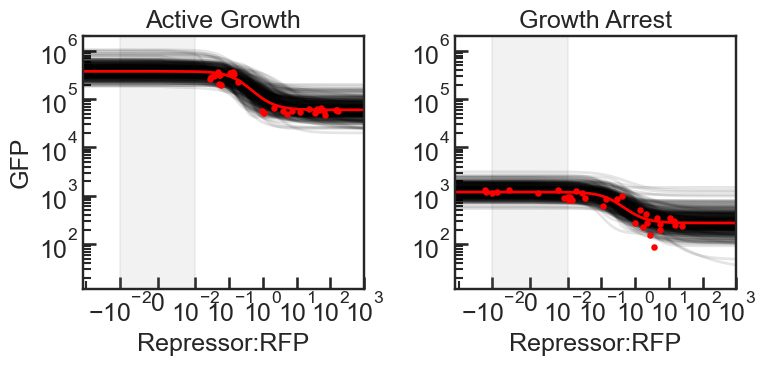

g14


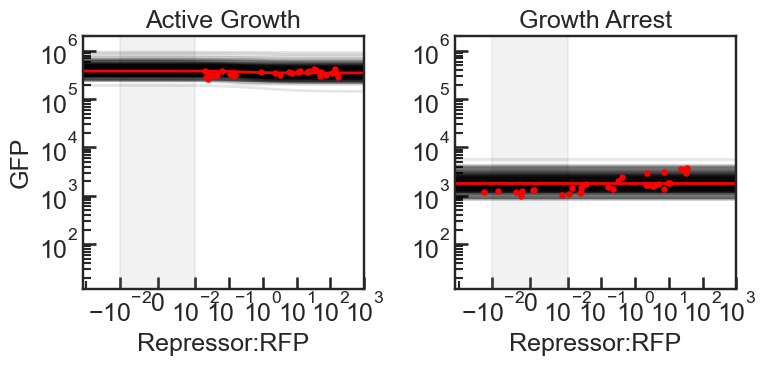

In [12]:

trajectories_to_plot = 300

med_sample_ls = []

for grna in grnas:
    med_sample_one = []
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians[(df_medians['gRNA'] == grna) &
                             (df_medians['Media'] == media)]
        
        filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        med_sample_one.append(med_sample)
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')

        # Test plot with original K=0.1 value
        # test_sample = [np.median(betas),
        #                np.median(alphas),
        #                0.1,
        #                np.median(ns)]
        # xsmooth = np.logspace(-3,3,100)
        # ysmooth = np.log(Hill_rep_fun(xsmooth,test_sample))
        # xsmooth = np.insert(xsmooth, 0, -10)
        # ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, test_sample)))
        # ax[m].plot(xsmooth, np.exp(ysmooth), c='b')
        
        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        # sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
        #                 color='r', ax=ax[m], zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        # ax[m].set_xscale('log')
        # ax[m].set_title(media)
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    med_sample_ls.append(med_sample_one)
    
    # ymin1, ymax1 = ax[0].get_ylim()
    # ymin2, ymax2 = ax[1].get_ylim()
    # yminmin = np.min([ymin1, ymin2])
    # ymaxmax = np.max([ymax1, ymax2])

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    plt.savefig('./figs/BPEplots/D_'+grna+'.png')
    plt.show()
        
        
        

### Generate just a single corner plot for main text figure

Fig. 4a

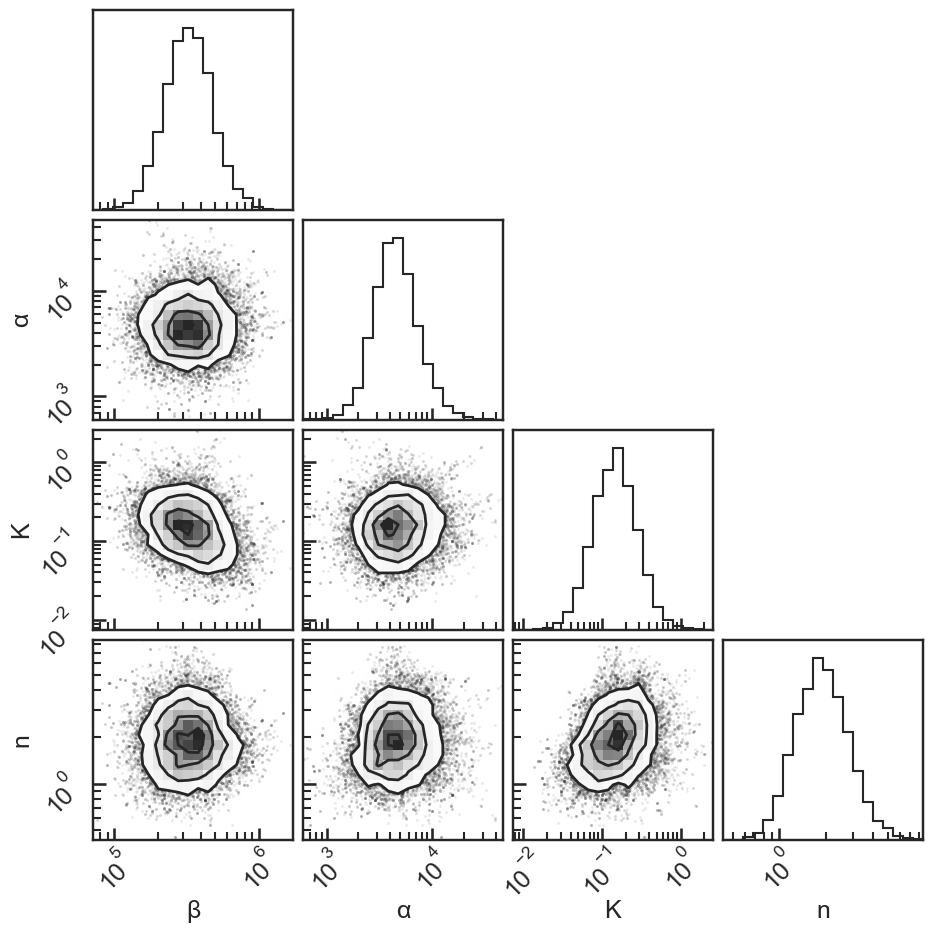

In [16]:
filename = './MCMC_outputs/'+'g3'+'_'+'M9'+'_32_10000.pkl'
with open(filename, 'rb') as f:
    sampler = pickle.load(f)
f.close()
flat_samples = sampler.get_chain(discard=9000, flat=True)

import corner
fig = corner.corner(flat_samples,
                   labels=['β',
                           'α',
                           'K',
                           'n'],
    axes_scale=['log', 'log', 'log', 'log'],
                   )


## GFP levels in certain conditions

Fig. 3d

In [17]:
#recreate another df_medians-like dataframe but only with the relevant conditions

df_ls = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]

            # get Blank condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+'Blank']
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG –, atc –', grna, rep, media, med_gfp, med_rfp]
            df_ls.append(row_to_append)

            # get no-atc condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+'0']
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG +, atc –', grna, rep, media, med_gfp, med_rfp]
            df_ls.append(row_to_append)

            # get max-atc condition
            fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[-1]]
            gfps = np.array(fcs[:,5])
            rfps = np.array(fcs[:,7])
            med_gfp = np.median(gfps)
            med_rfp = np.median(rfps)
            
            row_to_append = ['IPTG +, atc +', grna, rep, media, med_gfp, med_rfp] 
            df_ls.append(row_to_append)

        df_3cond_medians = pd.DataFrame(df_ls, columns=['Condition','gRNA','Replicate','Media','median GFP', 'median RFP'])

# throw out g9 rep1 because it has signs of measurement error
df_3cond_medians = df_3cond_medians[(df_3cond_medians.gRNA != 'g9') | (df_3cond_medians.Replicate != 1)]

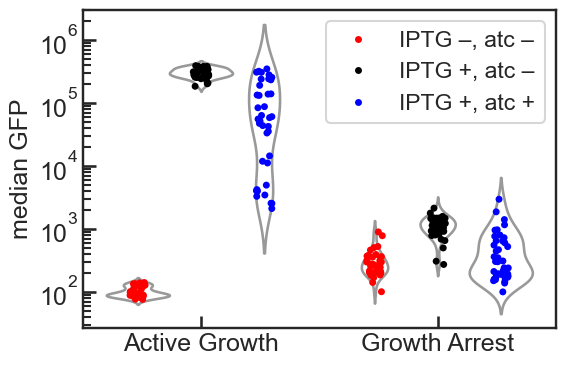

In [18]:
fig, ax = plt.subplots(figsize=(6,4))
sns.stripplot(data=df_3cond_medians,
              x='Media', y='median GFP',
              hue='Condition', dodge=True,
              ax=ax,
             )
sns.violinplot(data=df_3cond_medians,
               x='Media', y='median GFP',
               hue='Condition', dodge=True,
               ax=ax, legend=False, log_scale=True,
               inner=None,
               palette=['w','w','w']
              )
plt.gca().set_yscale('log')
plt.gca().set_xticklabels(['Active Growth', 'Growth Arrest'])
plt.xlabel('')

handles, labels = ax.get_legend_handles_labels()
ax.legend(title='')
# ax.legend(handles=handles[1:], labels=labels[1:])

# plt.gca().set_ylim((3e1,3e7)) # puts some white space above the data if you want to make significance stars
plt.tight_layout()
plt.savefig('./figs/Dgates_GFP_medians.pdf')
plt.show()


### Compute summary statistics

In [19]:
# is there a statistically significant difference between IPTG- and IPTG+ conditions?

m9_blank = df_3cond_medians[(df_3cond_medians.Condition=='IPTG –, atc –') & (df_3cond_medians.Media=='M9')]['median GFP'].values
m9_high = df_3cond_medians[(df_3cond_medians.Condition=='IPTG +, atc –') & (df_3cond_medians.Media=='M9')]['median GFP'].values
cl_blank = df_3cond_medians[(df_3cond_medians.Condition=='IPTG –, atc –') & (df_3cond_medians.Media=='CL')]['median GFP'].values
cl_high = df_3cond_medians[(df_3cond_medians.Condition=='IPTG +, atc –') & (df_3cond_medians.Media=='CL')]['median GFP'].values

m9_ttest = stats.ttest_rel(np.log10(m9_blank), np.log10(m9_high))
cl_ttest = stats.ttest_rel(np.log10(cl_blank), np.log10(cl_high))

print(m9_ttest)
print(cl_ttest)
print()

# what is the difference in geometric means between the distributions?
print(stats.gmean(m9_blank))
print(stats.gmean(m9_high))
print(stats.gmean(m9_high)/stats.gmean(m9_blank))
print()
print(stats.gmean(cl_blank))
print(stats.gmean(cl_high))
print(stats.gmean(cl_high)/stats.gmean(cl_blank))
print()
print(stats.gmean(cl_blank)/stats.gmean(m9_blank))
print(stats.gmean(m9_high)/stats.gmean(cl_high))

TtestResult(statistic=-264.31646053328893, pvalue=3.1907763435316034e-62, df=37)
TtestResult(statistic=-17.11965211413997, pvalue=3.601986675958946e-19, df=37)

99.08155946962371
298698.20570505934
3014.6700082635844

276.46446251252826
1038.0387360962081
3.754691386597901

2.790271610503732
287.75246560488205


## Analysis of noise

### Plot KDEs

Fig. 3e

In [21]:
# make a KDE of GFP values for each experimental condition

kdes_dict = dict()
var_ls_m9 = []
var_ls_cl = []
highvar_keys_ls = []

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls[rep-1]
            atcs = atcs_ls[rep-1][m]
            plot_inds = plot_inds_ls[rep-1][m]
            for a in range(1,len(atcs)): # ignore Blank values
                atc = atcs[a]

                fcs = fcs_gated_dict[media+'_'+grna+'_'+atc]
                loggfps = np.log10(np.array(fcs[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict[media+'_'+grna+'_'+atc] = kde

                if media == 'M9':
                    var_ls_m9.append(np.var(loggfps))
                elif media == 'CL':
                    var_ls_cl.append(np.var(loggfps))
                else:
                    print('problem!')

                if np.var(loggfps) > 0.08:
                    highvar_keys_ls.append(media+'_'+grna+'_'+atc+'r'+str(rep))


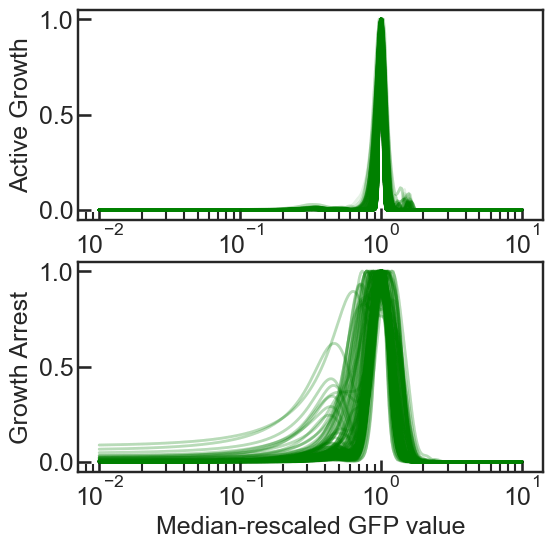

In [30]:
# Plot KDE of GFP values for each experimental condition

xrange = np.logspace(-2,1,300)

num_m9_multimodals = 0
num_cl_multimodals = 0

cross_ls_m9 = []
cross_ls_cl = []
width_ls_m9 = []
width_ls_cl = []
# Plot all non-Blank conditions
fig, ax = plt.subplots(2, 1, figsize=(6,6))
for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde = kdes_dict[media+'_'+grna+'_'+atc]
                yvals = kde(xrange)
                yvals /= np.max(yvals)
                c='g'
                
                # does it appear to be multimodal?
                ydervals = np.diff(yvals)
                lefthalfind = np.where(xrange>0.9)[0][0] 
                lefthalf_ydervals = ydervals[:lefthalfind]
                if np.min(lefthalf_ydervals) < -0.005:
                    if media == 'M9':
                        num_m9_multimodals += 1
                    elif media == 'CL':
                        num_cl_multimodals += 1
                        
                    multimodal_key_ls.append(media+'_'+grna+'_'+atc+'r'+str(rep))
                    c='g'
                    ax[m].plot(xrange, yvals, alpha=0.1, c=c)
                else:
                    ax[m].plot(xrange, yvals, alpha=0.1, c=c)
                    # pass


                # store x values at which KDE crosses 0.2 on the up and the down
                left_x = np.where(yvals > 0.2)[0][0]
                right_x = np.where(yvals > 0.2)[0][-1]

                if media == 'M9':
                    cross_ls_m9.append((xrange[left_x], xrange[right_x]))
                    width_ls_m9.append(xrange[right_x]/xrange[left_x])
                elif media == 'CL':
                    cross_ls_cl.append((xrange[left_x], xrange[right_x]))
                    width_ls_cl.append(xrange[right_x]/xrange[left_x])
                else:
                    print('problem!')
                

ax[0].set_xscale('log')
ax[1].set_xscale('log')
ax[0].set_ylabel('Active Growth')
ax[1].set_ylabel('Growth Arrest')
ax[1].set_xlabel('Median-rescaled GFP value')

plt.savefig('./figs/Dgates_GFP_KDEs.pdf')
plt.show()



What percent of distributions exhibited notable multimodality?

In [31]:
print(num_m9_multimodals/len(cross_ls_m9))
print(num_cl_multimodals/len(cross_ls_cl))

0.0
0.23776223776223776


### Plot distribution widths

Fig. 3f

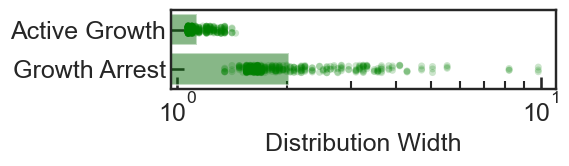

In [24]:

plt.figure(figsize=(6,2))
sns.barplot([stats.gmean(width_ls_m9), stats.gmean(width_ls_cl)], palette=['g','g'], alpha=0.5, orient='h')
sns.stripplot([width_ls_m9, width_ls_cl], palette=['g','g'], alpha=0.2, orient='h')
plt.gca().set_xscale('log')
plt.gca().set_yticklabels(['Active Growth','Growth Arrest'])
plt.xlabel('Distribution Width')
plt.tight_layout()
plt.savefig('./figs/Dgates_GFP_KDE_widths.pdf')
plt.show()


In [25]:
print('Gmeans of distribution widths')
print(stats.gmean(width_ls_m9))
print(stats.gmean(width_ls_cl))
print(stats.gmean(width_ls_cl)/stats.gmean(width_ls_m9))

Gmeans of distribution widths
1.1330178009702339
2.030480185443433
1.7920991035663143


## Analysis of BPE-derived parameter estimates

Fig. 4b

Requires prior running of the BPE_with_MCMC_Dgates notebook.

In [9]:
medias = ['M9', 'CL']
reps = [1,2,3]
grnas = ['g1','g2','g3','g4','g5','g6',
         'g8','g9','g10','g11','g12','g13','g14']

In [10]:
# width for violin plots so that distributions
# represent 33bp dCas9 footprint width
vw = 15

In [11]:
medias = ['M9', 'CL']

data = []
for grna in grnas:
    if grna != 'g14':
        strand = strand_dict[grna]
        PAM = PAM_dict[grna]
        foldrep_ls = []
        betas_ls = []
        alphas_ls = []
        Ks_ls = []
        ns_ls = []
        for m in range(len(medias)):
            media = medias[m]
            
            filename = './MCMC_outputs/'+grna+'_'+media+'_32_10000.pkl'
            with open(filename, 'rb') as f:
                sampler = pickle.load(f)
            f.close()
            flat_samples = sampler.get_chain(discard=9000, flat=True)
            
            betas = flat_samples[:,0]
            alphas = flat_samples[:,1]
            Ks = flat_samples[:,2]
            ns = flat_samples[:,3]
            foldreps = betas/alphas + 1 # <- Fold Change is (beta+alpha)/alpha

            foldrep_ls.append(foldreps)
            betas_ls.append(betas)
            alphas_ls.append(alphas)
            Ks_ls.append(Ks)
            ns_ls.append(ns)
            
            for i in range(len(foldreps)):
                data.append([media, PAM, strand, foldreps[i],
                             betas[i], alphas[i],Ks[i], ns[i]])
        
        foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
        betas_delta = betas_ls[1]/betas_ls[0]
        alphas_delta = alphas_ls[1]/alphas_ls[0]
        Ks_delta = Ks_ls[1]/Ks_ls[0]
        ns_delta = ns_ls[1]/ns_ls[0]
        for i in range(len(foldreps_delta)):
            data.append(['Delta', PAM, strand, foldreps_delta[i],
                         betas_delta[i], alphas_delta[i],
                         Ks_delta[i], ns_delta[i]])

df = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                 'Fold Repression', 'Beta', 'Alpha',
                                 'K', 'n'])

### Plot Fold Repression, K, and n for the M9 condition

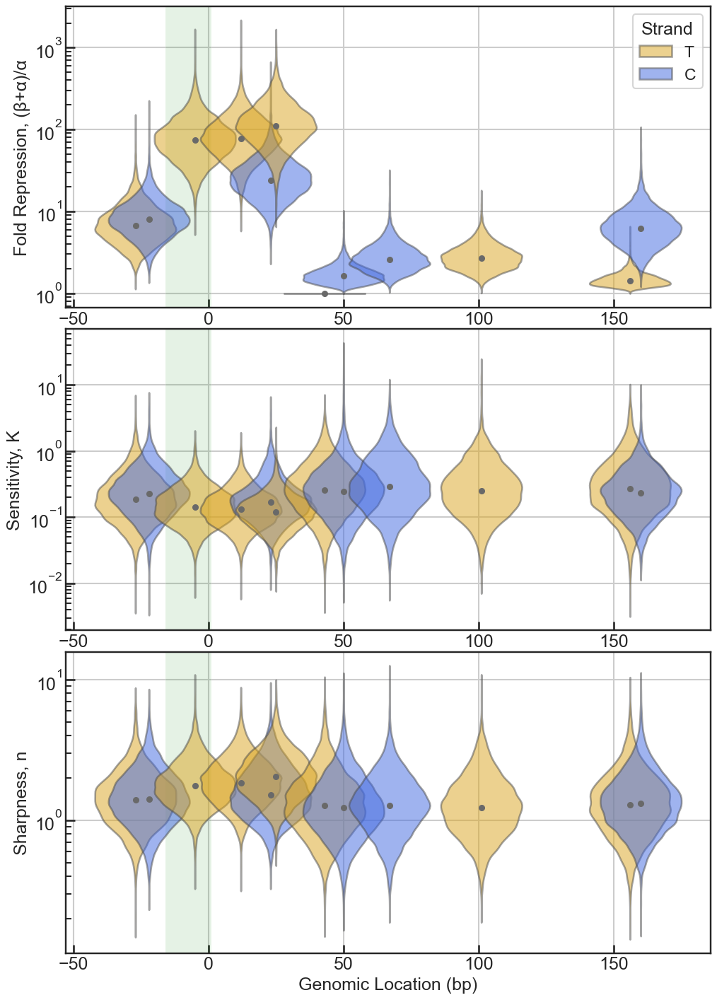

In [12]:
# Plot out fold change, K, and n for M9

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)

# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=vw,
              )

# plot medians
FR_medians = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
K_medians = df[df.Media=='M9'].groupby('Location')['K'].median()
n_medians = df[df.Media=='M9'].groupby('Location')['n'].median()
ax1.scatter(np.array(FR_medians.index), np.array(FR_medians), c='dimgrey')
ax2.scatter(np.array(K_medians.index), np.array(K_medians), c='dimgrey')
ax3.scatter(np.array(n_medians.index), np.array(n_medians), c='dimgrey')

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(title='Strand', handles=handles, labels=['T','C'])

# ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, (β+α)/α')
ax2.set_ylabel('Sensitivity, K')
ax3.set_ylabel('Sharpness, n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.tight_layout(pad=0.1)
plt.savefig('./figs/Dgates_BPE_parameters_M9.pdf')
plt.show()

### Plot Fold Repression, K, and n for the CLim condition

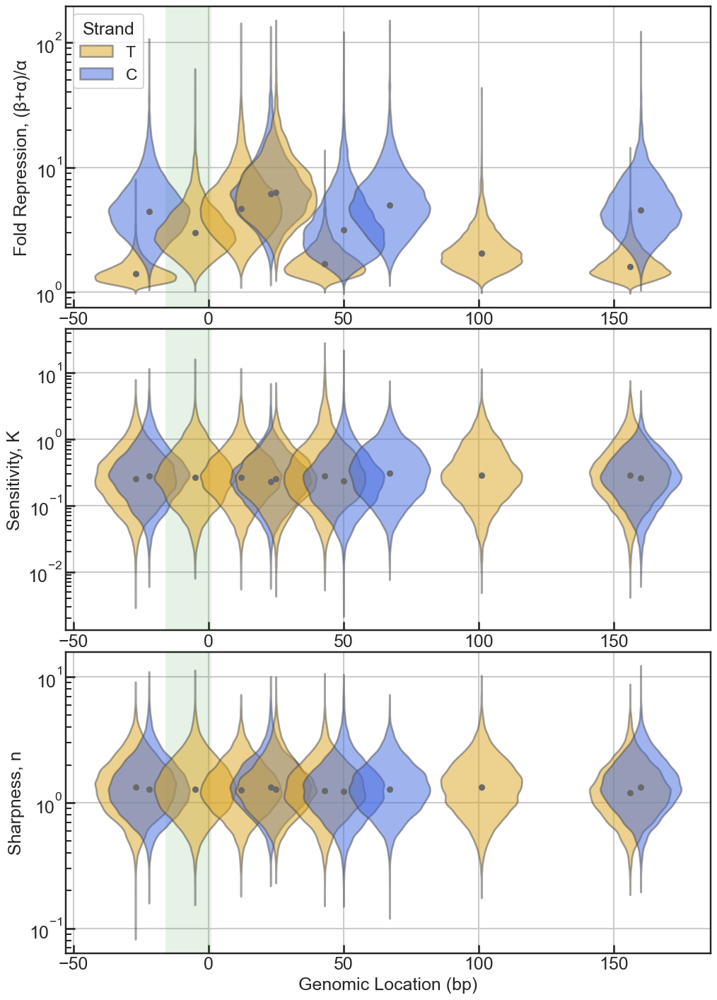

In [13]:
# Plot out fold change, K, and n for CL

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2)
ax3 = fig.add_subplot(3, 1, 3)

# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=df[df.Media == 'CL'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=vw,
              )

# plot medians
FR_medians = df[df.Media=='CL'].groupby('Location')['Fold Repression'].median()
K_medians = df[df.Media=='CL'].groupby('Location')['K'].median()
n_medians = df[df.Media=='CL'].groupby('Location')['n'].median()
ax1.scatter(np.array(FR_medians.index), np.array(FR_medians), c='dimgrey')
ax2.scatter(np.array(K_medians.index), np.array(K_medians), c='dimgrey')
ax3.scatter(np.array(n_medians.index), np.array(n_medians), c='dimgrey')

handles, labels = ax1.get_legend_handles_labels()
ax1.legend(title='Strand', handles=handles, labels=['T','C'])

# ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
# ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, (β+α)/α')
ax2.set_ylabel('Sensitivity, K')
ax3.set_ylabel('Sharpness, n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
plt.tight_layout(pad=0.1)
plt.savefig('./figs/Dgates_BPE_parameters_CL.pdf')
plt.show()

### Statistics on parameter values

Statistics on Fold Repression

In [14]:
FR_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['Fold Repression'].median())
FR_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['Fold Repression'].median())

print(FR_medians_m9)
print(min(FR_medians_m9))
print(max(FR_medians_m9))
print(FR_medians_cl)
print(min(FR_medians_cl))
print(max(FR_medians_cl))

[  6.64661771   8.01735743  73.79723749  77.85963811  24.15818962
 110.66177149   1.           1.65073537   2.60511303   2.70016248
   1.43419431   6.17910321]
1.0000000000040545
110.66177148776995
[1.39788151 4.43305479 2.97773267 4.69162948 6.1651078  6.29228678
 1.68459681 3.15903761 4.97365692 2.052022   1.59596551 4.54302348]
1.3978815149765307
6.292286778801221


Statistics on $n$

In [15]:
n_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['n'].median())
n_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['n'].median())

print(n_medians_m9)
print(min(n_medians_m9))
print(max(n_medians_m9))
print(n_medians_cl)
print(min(n_medians_cl))
print(max(n_medians_cl))

[1.39798695 1.40620976 1.7620852  1.85530299 1.51749762 2.0391944
 1.26968674 1.22497588 1.27890624 1.23238548 1.28149288 1.32114264]
1.2249758769592556
2.039194399403291
[1.32383494 1.27493136 1.28380321 1.25940348 1.32821429 1.27267296
 1.24759892 1.23622458 1.28425434 1.32573575 1.20203975 1.33894599]
1.2020397549220236
1.3389459901466902


Statistics on $K$

In [16]:
K_medians_m9 = np.array(df[df.Media=='M9'].groupby('Location')['K'].median())
K_medians_cl = np.array(df[df.Media=='CL'].groupby('Location')['K'].median())

print(K_medians_m9)
print(max(K_medians_m9)/min(K_medians_m9))
print()
print(K_medians_cl)
print(max(K_medians_cl)/min(K_medians_cl))
print()
# First 6 gates versus remaining 6 gates
print(stats.gmean(K_medians_m9[:6]), stats.gmean(K_medians_m9[6:]))

[0.18443719 0.22839738 0.1417136  0.13259615 0.16869809 0.11853717
 0.25495278 0.24551709 0.29064409 0.25079461 0.26761511 0.23009624]
2.451923563427929

[0.2533165  0.27983626 0.26356242 0.2636774  0.23130176 0.25296087
 0.27912566 0.23441984 0.30673675 0.2873834  0.28482091 0.2576858 ]
1.326132347479943

0.15845567601342314 0.25592156854790477


### Plot of how parameters shift between growth conditions

Fig. 4c

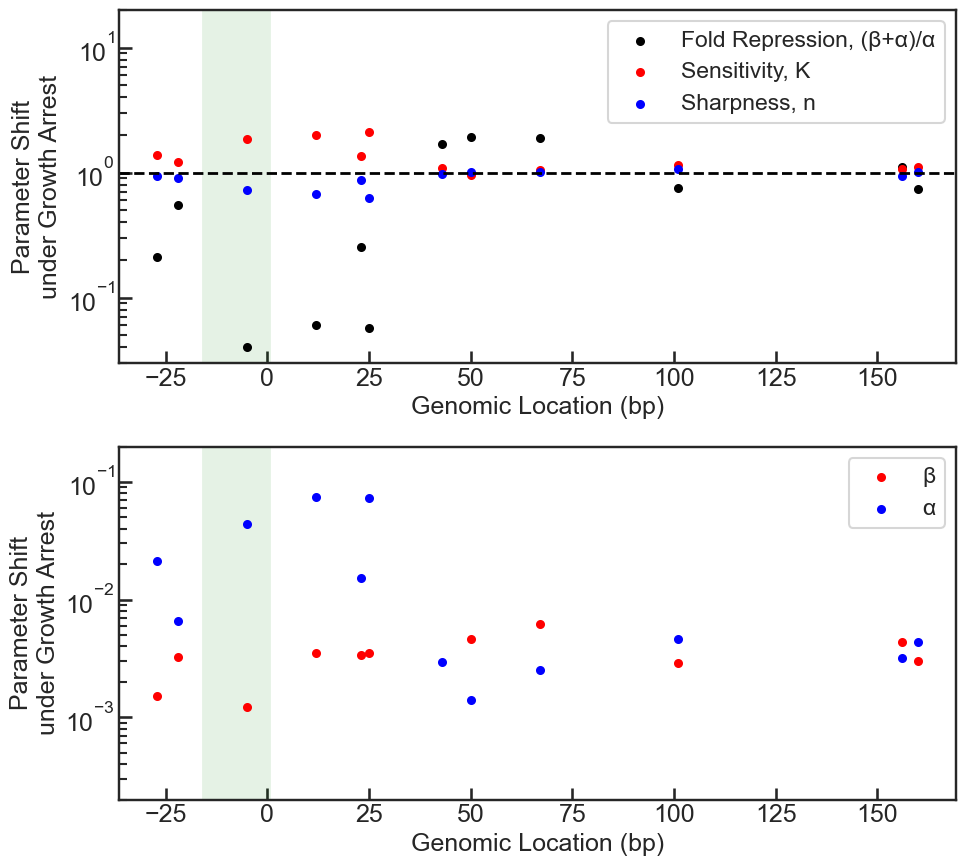

In [17]:
m9_FCs = df[df.Media=='M9'].groupby('Location')['Fold Repression'].median()
m9_betas = df[df.Media=='M9'].groupby('Location')['Beta'].median()
m9_alphas = df[df.Media=='M9'].groupby('Location')['Alpha'].median()
m9_Ks = df[df.Media=='M9'].groupby('Location')['K'].median()
m9_ns = df[df.Media=='M9'].groupby('Location')['n'].median()
cl_FCs = df[df.Media=='CL'].groupby('Location')['Fold Repression'].median()
cl_betas = df[df.Media=='CL'].groupby('Location')['Beta'].median()
cl_alphas = df[df.Media=='CL'].groupby('Location')['Alpha'].median()
cl_Ks = df[df.Media=='CL'].groupby('Location')['K'].median()
cl_ns = df[df.Media=='CL'].groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(10,9))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((3e-2,2e1))
ax[0].legend()
ax[0].set_xlabel('Genomic Location (bp)')
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((2e-4,2e-1))
ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/Dgates_BPE_parameter_shifts.pdf')
plt.show()



### Statistics on per-gate shifts

In [18]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 6)
# delta_FCs = np.delete(delta_FCs, 6) # you can calculate FC here so it's ok
delta_ns = np.delete(delta_ns, 6)
delta_betas = np.delete(delta_betas, 6)
delta_alphas = np.delete(delta_alphas, 6)


In [19]:

print(delta_Ks)
print(stats.gmean(delta_Ks[:6]))
print(1/stats.gmean(delta_Ks[6:]))
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs[:6]))
print(stats.gmean(delta_FCs[6:]))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.37345671 1.22521661 1.85982448 1.98857505 1.37109884 2.13402145
 0.95480048 1.05536894 1.14589146 1.06429305 1.11990446]
1.6220026382021184
0.9381223344500013
1.340241018165518

[0.21031472 0.55293216 0.04035019 0.06025753 0.25519743 0.05686053
 1.68459681 1.91371535 1.90919045 0.75996241 1.11279587 0.73522376]
7.903492824869778
1.250666795742375

[0.94695801 0.9066438  0.72857045 0.67881284 0.87526614 0.62410575
 1.0091828  1.00418178 1.07574763 0.93799956 1.01347572]
[1.05601304 1.10296899 1.37255086 1.47316012 1.14250963 1.60229255
 0.99090076 0.99583563 0.92958606 1.06609858 0.98670346]
1.1383667237590327

319.90538010812287
98.58840998012627


In [20]:
print(1/delta_betas)
print(1/delta_alphas)
print(1/delta_FCs)

[657.37423345 308.80544653 816.99086611 283.79702469 297.90147635
 286.69689041 215.21920425 161.28264818 343.10023677 227.47882487
 329.7524396 ]
[ 46.6248714  150.53107602  22.56364415  13.43153433  65.67951038
  13.72729457 712.83254757 399.79954968 217.77946085 312.97850193
 229.57769876]
[ 4.75477903  1.80854012 24.78302976 16.5954363   3.91853483 17.58689255
  0.59361385  0.52254375  0.52378221  1.31585455  0.89863741  1.36013015]
